# **Лабораторная работа 2. Классификация. Нейронные сети**

## **Введение**

### **Цель работы:** 
изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard. 

### **Постановка задачи:**

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

    a) Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);

    b) Деревья решений (Decision Tree);

    c) Линейный дискриминантный анализ (Linear Discriminant Analysis);

    d) Метод опорных векторов (Support Vector Machines);

    e) Метод ближайших соседей (k-Nearest Neighbors);

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

    a) Accuracy (точность),

    b) Precision (доля правильно классифицированных положительных примеров),

    c) Recall (чувствительность, доля верно найденных положительных примеров),

    d) F1-Score (среднее гармоническое precision и recall),

    e) Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.



# **Описание датасета**
В качестве исходных данных используется открытый набор данных Student_Depression_Dataset.csv, загруженный с платформы Kaggle [1]. Датасет содержит сведения о студентах, их социальном положении, условиях проживания, успеваемости и состоянии здоровья, а также целевую переменную, отражающую наличие или отсутствие депрессии.

Задача исследования заключается в построении моделей машинного обучения, способных классифицировать наблюдения на два класса в зависимости от значения целевой переменной:

- No (0) — депрессия отсутствует;

- Yes (1) — депрессия присутствует.

Таким образом, рассматривается задача бинарной классификации с учителем.

Для первоначального знакомства с данными воспользуемся библиотекой Pandas. Сначала загрузим CSV-файл, изучим структуру таблицы, типы переменных и выведем несколько первых наблюдений.

In [55]:
import pandas as pd

SEED = 11

df = pd.read_csv('Student_Depression_Dataset.csv')

df.info()
print(f"Количество записей: {df.shape[0]}\nКоличество характеристик: {df.shape[1]}")
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 722.9 KB
Количество записей: 4464
Количество характеристик: 13


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


Набор данных содержит 4464 наблюдения и 13 переменных. Из них 12 переменных используются в качестве признаков, а одна – Depression – является целевой. Все признаки подробно расписаны в таблице 1.

Таблица 1 – Описание признаков
| переменная | Тип | Подтип | Описание |
| ----------- | ----------- | ----------- | ----------- |
| Gender | Категориальная | Бинарная | Пол респондента. |
| Age | Количественная | Дискретная | Возраст студента в годах . | 
| Family_background | Категориальная | Ордирная | Экономический или классовый статус семьи. |
| Relationship_status | Категориальная | Номинальная | Статус романтических отношений студента (холост/не замужем, сложные отношения, в отношениях). |
| Marital_status | Категориальная | Номинальная | Семейное положение студента (Не замужем, замужем, в разводе). | 
| Living_style | Категориальная | Бинарная | Текущие условия проживания (Один, с семьёй). | 
| Current_semester | Количественная | Дискретная | Семестр, в котором в настоящее время обучается студент.|
| CGPA | Количественная | Непрерывная | Совокупный средний балл успеваемости (академическая успеваемость). |
| friend_circle | Категориальная | Бинарная | Указывает, есть ли у респондента активный круг друзей (да/нет). |
| Health_condition | Категориальная | Ординальная | Общее физическое состояние здоровья (хорошее, нормальное, отклоняющееся от нормы, критическое). |
| Cost_without_study | Количественная | Дискретная | Оценка расходов на проживание/затрат помимо учебы. |
| Home_division | Категориальная | Номинальная | Домашний регион/округ респондента (например, Дакка, Читтагонг).|
| **Depression** | Категориальная | Бинарная | **Целевая переменная** – Указывает, испытывает ли респондент депрессию (да/нет). |



## **Первичный анализ**
Проведем первичный анализ наших признаков.

In [56]:
df.describe(include="all")

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
count,4464,4464.000000,4464,4464,4464,4464,4464.000000,4464.000000,4464,4464,4464.000000,4464,4464
unique,2,NaN,3,3,3,2,NaN,NaN,2,4,NaN,8,2
top,Female,NaN,Middle class,Single,Unmarried,Bachelor,NaN,NaN,Yes,Normal,NaN,Dhaka,No
freq,2462,NaN,2642,2803,3619,2449,NaN,NaN,3215,1787,NaN,1527,3263
mean,NaN,22.619176,NaN,NaN,NaN,NaN,5.401210,3.412753,NaN,NaN,11242.978271,NaN,NaN
std,NaN,2.022980,NaN,NaN,NaN,NaN,2.578476,0.385605,NaN,NaN,6640.144019,NaN,NaN
min,NaN,17.000000,NaN,NaN,NaN,NaN,0.000000,2.250000,NaN,NaN,0.000000,NaN,NaN
25%,NaN,21.000000,NaN,NaN,NaN,NaN,3.000000,3.150000,NaN,NaN,6100.000000,NaN,NaN
50%,NaN,23.000000,NaN,NaN,NaN,NaN,5.000000,3.490000,NaN,NaN,9500.000000,NaN,NaN
75%,NaN,24.000000,NaN,NaN,NaN,NaN,7.000000,3.700000,NaN,NaN,15439.000000,NaN,NaN


Вывод даёт сводку по всем признакам: 
- для числовых – количество значений, mean, std, квартили и границы.
- Также для числовы разброс значений сильно отличается: Age — десятки, CGPA — единицы, Cost_without_study — тысячи.
- для категориальных – количество значений, число уникальных значений, наиболее частую категорию и её частоту.
- целевая переменная Depression, чаще всего являются No на 3263 из 4464 (≈73.1%), что говорит о дисбалансе классов.

### **Визуализация распределений признаков**

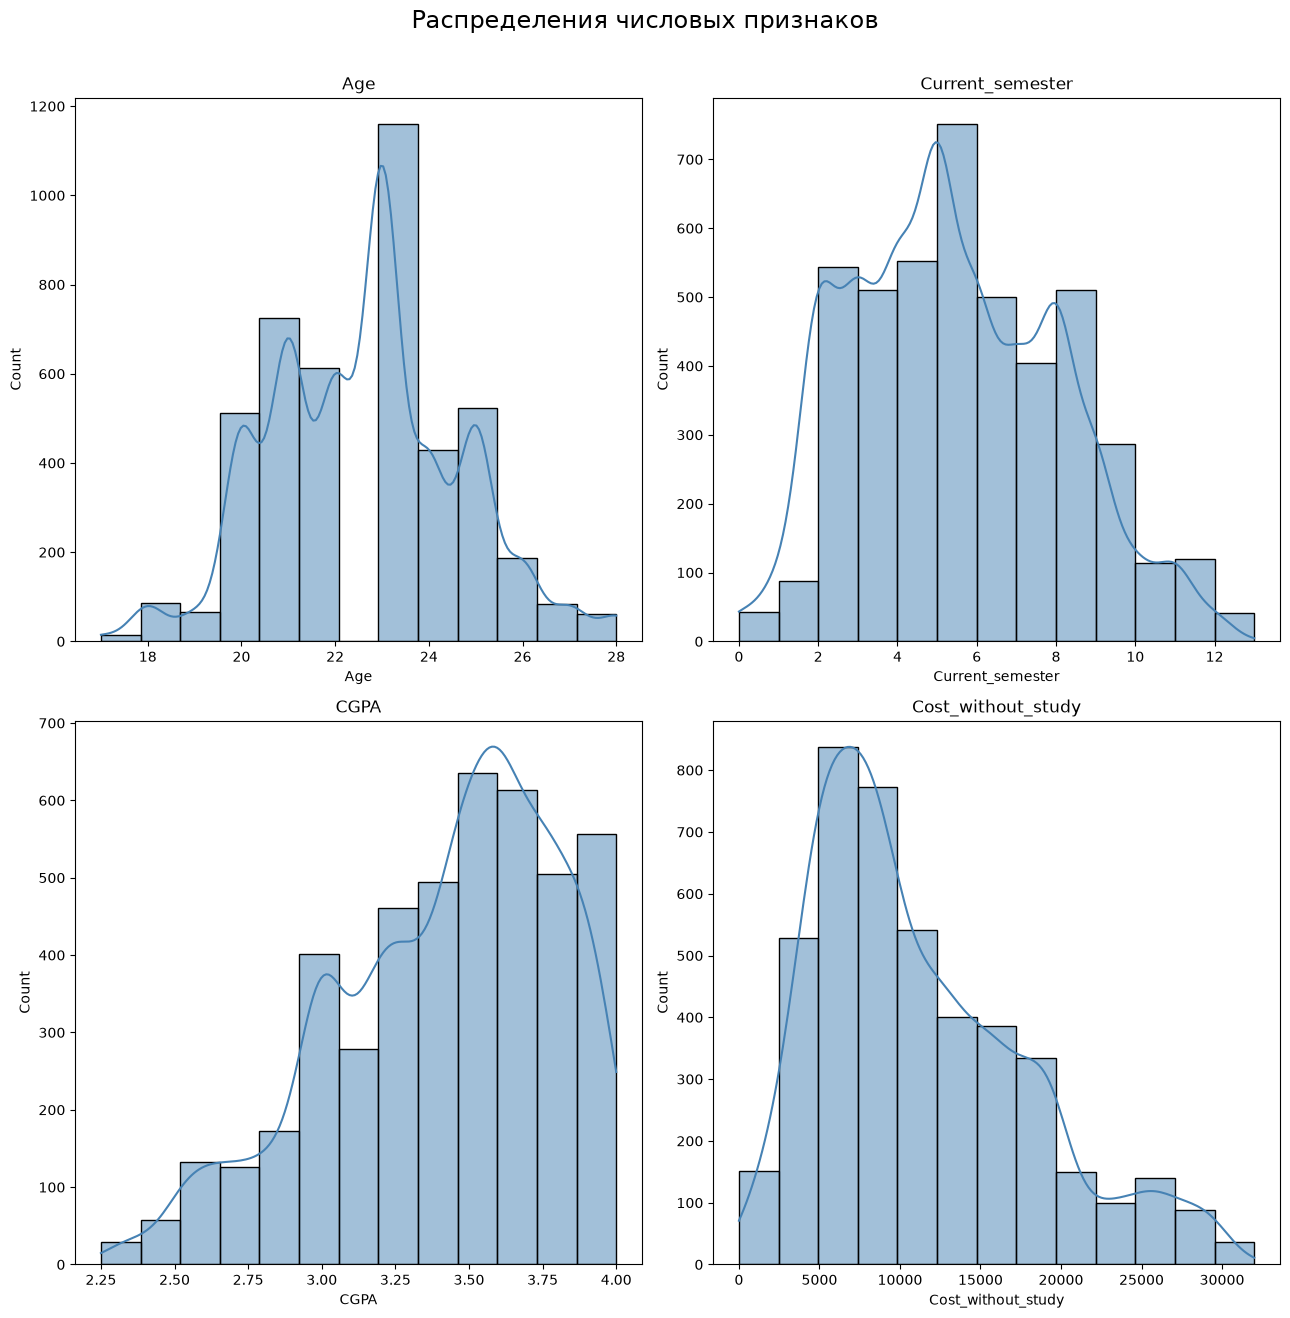

тест Шапиро-Уилка на нормальное распределение:
           Признак  W-статистика   p-value Нормальное?  Асимметрия  Эксцесс
               Age        0.9701 1.565e-29         Нет       0.152   -0.070
  Current_semester        0.9680 2.054e-30         Нет       0.312   -0.557
              CGPA        0.9576 3.221e-34         Нет      -0.605   -0.310
Cost_without_study        0.9359 3.415e-40         Нет       0.847    0.103


In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']

fig, axes = plt.subplots(2, 2, figsize=(13, 13))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, bins=13, ax=axes[i], color="steelblue")
    axes[i].set_title(f"{col}")
plt.suptitle("Распределения числовых признаков", fontsize=17, y=1.01)
plt.tight_layout()
plt.show()

from scipy.stats import shapiro

norm_report = []
for col in num_cols:
    sample = df[col].dropna().sample(min(5000, len(df)), random_state=SEED)
    w, p = shapiro(sample)
    norm_report.append({
        "Признак": col,
        "W-статистика": round(w, 4),
        "p-value": f"{p:.3e}",
        "Нормальное?": "Да" if p > 0.05 else "Нет",
        "Асимметрия": round(df[col].skew(), 3),
        "Эксцесс": round(df[col].kurtosis(), 3),
    })
norm_df = pd.DataFrame(norm_report)
print("тест Шапиро-Уилка на нормальное распределение:")

print(norm_df.to_string(index=False))

По тесту Шапиро–Уилка все четыре признака имеют p-value < 0.05, то есть гипотеза о нормальности отвергается. Наибольшая асимметрия у Cost_without_study (0.847), заметный эксцесс у Current_semester.



### **Распределение целевой переменной**

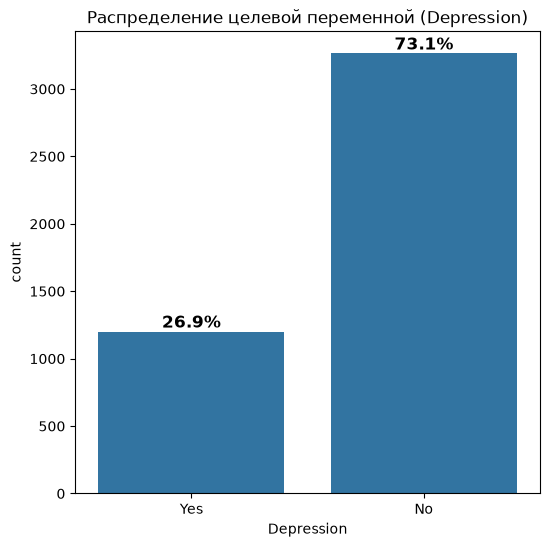

In [58]:
plt.figure(figsize=(6, 6))
ax = sns.countplot(data=df, x="Depression")
total = len(df)
for p in ax.patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(pct, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.title("Распределение целевой переменной (Depression)")
plt.show()

По результатам анализа видно, что классы распределены неравномерно. Большую часть выборки составляют студенты без признака депрессии — 73,1%, тогда как на класс с наличием депрессии приходится 26,9% наблюдений.

Таким образом, в датасете присутствует дисбаланс классов. Это необходимо учитывать при оценке качества классификационных моделей. Использование только метрики Accuracy может привести к неполному представлению о качестве классификации, поэтому дополнительно будут рассмотрены (в порядке приоритета):

- **F1-Score** — баланс между Precision и Recall. Растёт только тогда, когда обе метрики хороши, поэтому устойчив к дисбалансу классов и выбран основной метрикой при подборе гиперпараметров.

- **Recall** — доля найденных положительных среди всех реальных. Показывает, насколько полно модель выявляет больных: высокий Recall означает, что модель находит большинство реальных случаев депрессии. В скрининге депрессии пропустить человека опаснее, чем лишний раз направить здорового на проверку, поэтому Recall особенно важен.

- **Precision** — доля истинно положительных среди всех предсказанных положительных. Показывает, насколько можно доверять прогнозу «Есть депрессия». Высокий Precision — мало ложных тревог.

- **ROC-AUC** — площадь под ROC-кривой, что показывает, насколько хорошо модель разделяет два класса по вероятности, независимо от выбранного порога (0.5 — случайное угадывание, 1.0 — идеальное разделение). Удобна для сравнения моделей между собой.

- **Accuracy** — присутствует дисбаланс классов, поэтому Accuracy не будет отражать реальное качество модели и используется только справочно.



## **Проверка на пропуски и дубликаты**

In [59]:
print("Пропуски:\n", df.isnull().sum())
print("Дубликаты:", df.duplicated().sum())

Пропуски:
 Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64
Дубликаты: 0


По результатам проверки установлено, что в датасете отсутствуют пропущенные значения и полные дубликаты. Следовательно, удаление записей или заполнение пропусков на данном этапе не требуется.



# **Подготовка данных**
## **Кодирование признаков**
Большинство алгоритмов машинного обучения библиотеки Scikit-Learn работают с числовыми данными. Поэтому перед обучением моделей необходимо преобразовать категориальные переменные в числовой формат.

Для этого применяются следующие способы кодирования:

- Бинарное кодирование — для признаков, принимающих два возможных значения. Каждой категории присваивается числовое значение 0 или 1.

- Порядковое кодирование — для категориальных признаков, значения которых имеют естественный порядок. Числовые значения присваиваются в соответствии с этим порядком.

- One-Hot Encoding — для номинальных признаков, категории которых не имеют естественного порядка. Каждая категория преобразуется в отдельный бинарный столбец.

In [60]:
import numpy as np

df['Depression'] = df['Depression'].map({
    'No': 0,
    'Yes': 1
})

binary_mapping = {
    'Gender': {'Female': 0, 'Male': 1},
    'Living_style': {'Bachelor': 0, 'Family': 1},
    'friend_circle': {'No': 0, 'Yes': 1}
}

for col, mapping in binary_mapping.items():
    df[col] = df[col].map(mapping)

df['Family_background'] = df['Family_background'].map({
    'Lower Middle class': 0,
    'Middle class': 1,
    'Rich class': 2
})

df['Health_condition'] = df['Health_condition'].map({
    'Good': 0,
    'Normal': 1,
    'Abnormal': 2,
    'Critical': 3
})

df = pd.get_dummies(
    df,
    columns=['Relationship_status', 'Marital_status', 'Home_division'],
    drop_first=True,
    dtype=int
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 21 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 4464 non-null   int64  
 1   Age                                    4464 non-null   int64  
 2   Family_background                      4464 non-null   int64  
 3   Living_style                           4464 non-null   int64  
 4   Current_semester                       4464 non-null   int64  
 5   CGPA                                   4464 non-null   float64
 6   friend_circle                          4464 non-null   int64  
 7   Health_condition                       4464 non-null   int64  
 8   Cost_without_study                     4464 non-null   int64  
 9   Depression                             4464 non-null   int64  
 10  Relationship_status_In a Relationship  4464 non-null   int64  
 11  Relationship_st

Итоговый размер датасета – (4464, 21). Теперь все признаки являются числовыми и готовы к дальнейшему анализу.

Целевая переменная Depression также преобразуется в бинарный формат: значение No заменяется на 0, а Yes — на 1.


## **Разделение выборки и стандартизация**

In [61]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Depression'])
y = df['Depression']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

scaler = MinMaxScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Train: {X_train_sc.shape}, Test: {X_test_sc.shape}")

Train: (3571, 20), Test: (893, 20)


**Разделение** в пропорции 80/20: 80% наблюдений используются для обучения моделей, а оставшиеся 20% — для проверки качества их работы. При разделении используется параметр stratify=y. Он обеспечивает сохранение исходного соотношения классов в обеих выборках

**Масштабирование** числовых признаков с помощью MinMaxScaler. Данный метод преобразует значения признаков к диапазону от 0 до 1. Масштабирование необходимо для алгоритмов, чувствительных к диапазону значений, — SVM, k-NN, LDA, а также MultinomialNB и ComplementNB, требующих неотрицательных признаков. MinMaxScaler обучается только на обучающей выборке, а к тестовой применяется только transform, чтобы избежать утечки данных.

# **Методы Классификации**
## **Наивный Байесовский классификатор**
Наивный байесовский классификатор — это семейство вероятностных алгоритмов машинного обучения, основанных на теореме Байеса. Алгоритм определяет вероятность принадлежности объекта к каждому из возможных классов и относит его к классу с наибольшей апостериорной вероятностью.

В работе исследуются 4 модификации:
- **GaussianNB** – Предполагает, что значения каждого признака внутри каждого класса распределены по нормальному закону
- **MultinomialNB** – Используется преимущественно для дискретных неотрицательных данных, представляющих собой частоты или количества событий.
- **ComplementNB** – модификация MultinomialNB, разработанная для несбалансированных датасетов.
- **BernoulliNB** – предназначен для бинарных (булевых) признаков.



### **Построение базовых моделей**
Сначала обучим все четыре классификатора со стандартными параметрами, не выполняя дополнительную настройку гиперпараметров и сравним их.

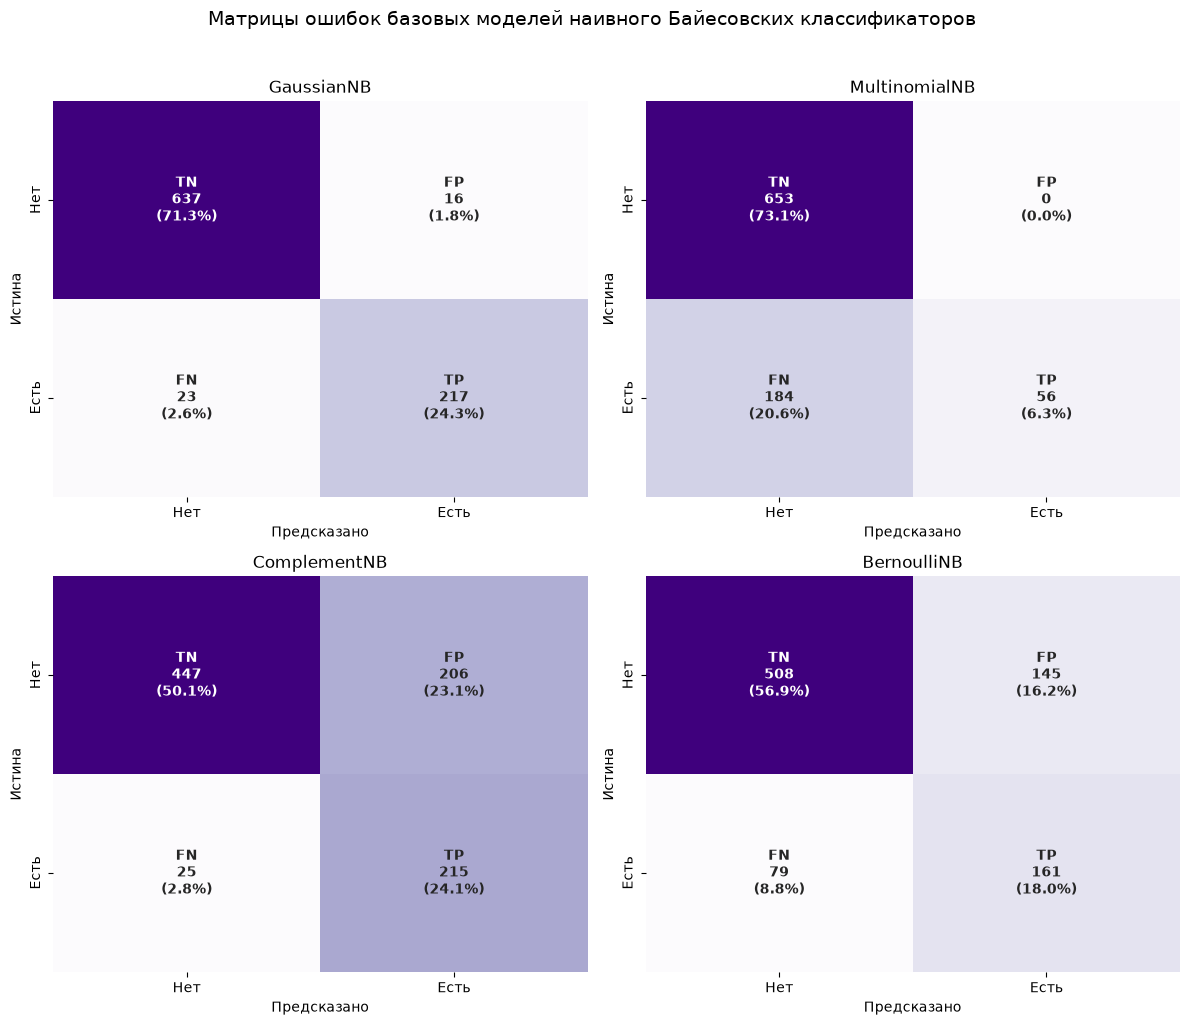

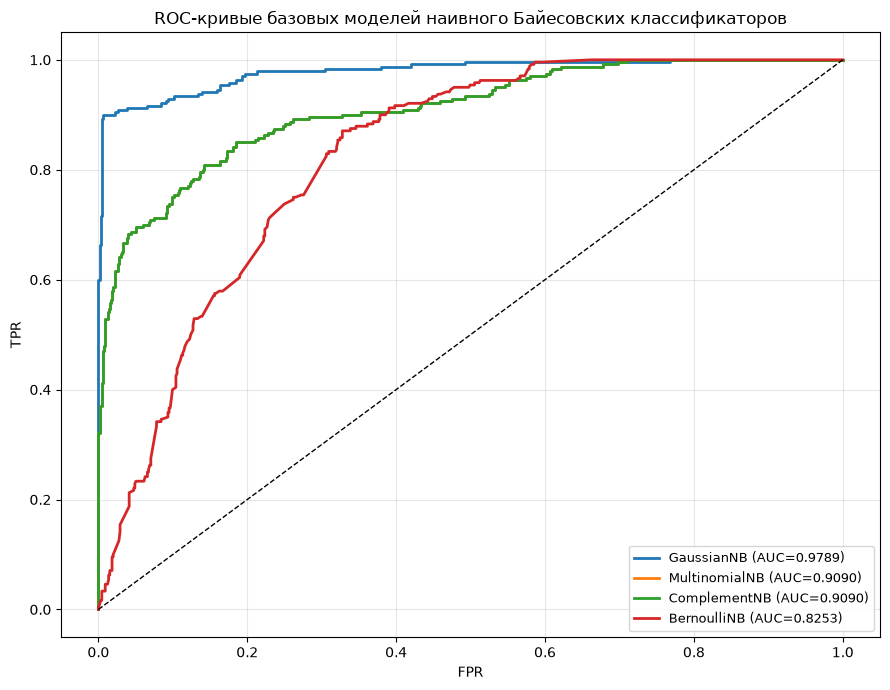

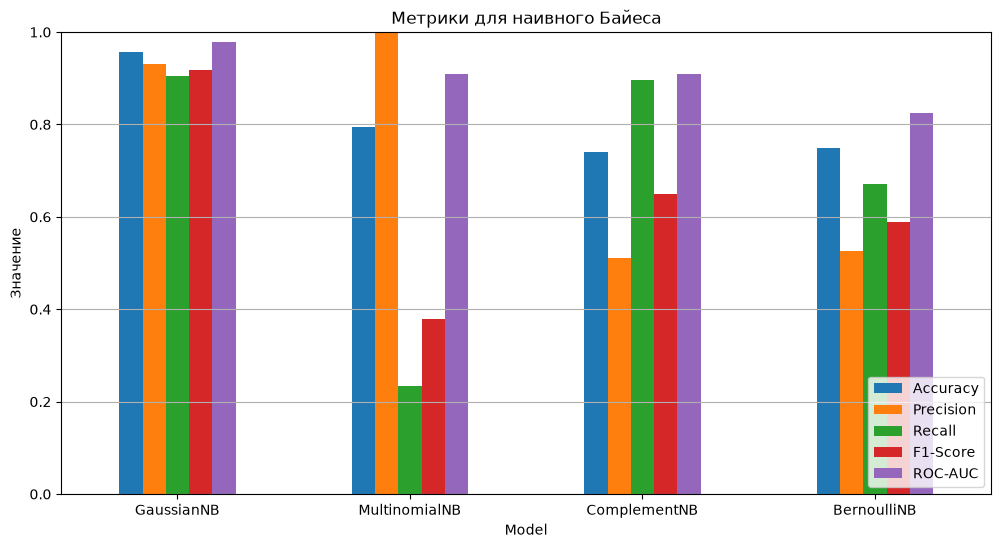

Вывод метрик базовых моделей наивного Байеса по F1-Score:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,GaussianNB,0.9563,0.9313,0.9042,0.9175,0.9789
1,ComplementNB,0.7413,0.5107,0.8958,0.6505,0.9090
2,BernoulliNB,0.7492,0.5261,0.6708,0.5897,0.8253
3,MultinomialNB,0.7940,1.0000,0.2333,0.3784,0.9090


In [62]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, auc, confusion_matrix)
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB

def compute_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1-Score":  f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_true, y_prob),
    }

def fit_and_evaluate(model, name, X_tr, y_tr, X_te, y_te,
                     results_store=None, roc_store=None):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    m = compute_metrics(y_te, y_pred, y_prob)
    m["Model"] = name
    if results_store is not None:
        results_store.append(m)
    if roc_store is not None:
        roc_store[name] = (y_te, y_prob)
    return y_pred, y_prob

def plot_roc_curves(store, title):
    plt.figure(figsize=(9, 7))
    for i, (name, (yt, yp)) in enumerate(store.items()):
        fpr, tpr, _ = roc_curve(yt, yp)
        plt.plot(fpr, tpr, lw=2, color=plt.cm.tab10.colors[i % 10],
                 label=f"{name} (AUC={auc(fpr, tpr):.4f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(title)
    plt.legend(loc="lower right", fontsize=9); plt.grid(alpha=.3)
    plt.tight_layout(); plt.show()

def plot_confusion_matrices(store, class_names=("Нет", "Есть"),
                            ncols=2, title="Матрицы ошибок"):
    n = len(store); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 5*nrows))
    axes = np.array(axes).flatten()
    for ax, (name, (yt, yp)) in zip(axes, store.items()):
        cm = confusion_matrix(yt, yp)
        labels = np.array([
            [f"TN\n{cm[0,0]}\n({cm[0,0]/len(yt):.1%})",
             f"FP\n{cm[0,1]}\n({cm[0,1]/len(yt):.1%})"],
            [f"FN\n{cm[1,0]}\n({cm[1,0]/len(yt):.1%})",
             f"TP\n{cm[1,1]}\n({cm[1,1]/len(yt):.1%})"]])
        sns.heatmap(cm, annot=labels, fmt="", cmap="Purples", cbar=False, ax=ax,
                    xticklabels=class_names, yticklabels=class_names,
                    annot_kws={"fontsize": 10, "fontweight": "bold"})
        ax.set_title(name); ax.set_xlabel("Предсказано"); ax.set_ylabel("Истина")
    for ax in axes[n:]: ax.axis("off")
    plt.suptitle(title, fontsize=14, y=1.02); plt.tight_layout(); plt.show()

def tune_model(estimator, grid, X_tr, y_tr, name, cv=5, scoring="f1"):
    gs = GridSearchCV(estimator, grid, cv=cv, scoring=scoring, n_jobs=-1, verbose=1)
    gs.fit(X_tr, y_tr)
    print(f"\n>>> {name}: лучшие параметры = {gs.best_params_}")
    print(f"    Лучший {scoring} (CV): {gs.best_score_:.4f}")
    return gs.best_estimator_, gs.best_params_, gs.best_score_

def show_results(store, sort_by="F1-Score", ascending=False):
    cols = ["Model", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
    d = pd.DataFrame(store)[cols].drop_duplicates(subset="Model")
    return d.sort_values(sort_by, ascending=ascending).round(4).reset_index(drop=True)

base_models = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": MultinomialNB(),
    "ComplementNB": ComplementNB(),
    "BernoulliNB": BernoulliNB(),
}

results_store = []
roc_store_base = {}
pred_store_base = {}
for name, mdl in base_models.items():
    y_pred, y_prob = fit_and_evaluate(
        mdl, name, X_train_sc, y_train, X_test_sc, y_test,
        results_store=results_store, roc_store=roc_store_base)
    pred_store_base[name] = (y_test, y_pred)

plot_confusion_matrices(pred_store_base, title="Матрицы ошибок базовых моделей наивного Байесовских классификаторов ")
plot_roc_curves(roc_store_base, title="ROC-кривые базовых моделей наивного Байесовских классификаторов")
metrics_df = pd.DataFrame(results_store).set_index('Model')
metrics_df.plot(kind='bar', figsize=(12, 6))
plt.title('Метрики для наивного Байеса'); plt.ylabel('Значение')
plt.ylim(0, 1); plt.grid(axis='y'); plt.xticks(rotation=0)
plt.legend(loc='lower right'); plt.show()

df_base = show_results(results_store)
print("Вывод метрик базовых моделей наивного Байеса по F1-Score:")
df_base

Выводы:
-    **GaussianNB** резко лидирует. Несмотря на то, что общие распределения признаков ненормальны (это было видно по Шапиро–Уилку). F1-Score составляет 0.9175, а ROC-AUC — 0.9789. Модель хорошо распознаёт оба класса.

-   **MultinomialNB** имеет Precision = 1.0, но Recall всего 0.2333. Это означает, что модель практически не ошибается, когда предсказывает наличие депрессии, но находит лишь небольшую часть всех положительных объектов.

-  **ComplementNB** демонстрирует высокий Recall = 0.8958, однако Precision составляет 0.5107. Модель находит большинство положительных объектов, но часто ошибочно относит к ним студентов без депрессии. Такой профиль подходит, если цена пропуска выше цены ложной тревоги, но не для финального диагноза.

- **BernoulliNB** показывает промежуточные результаты, но уступает GaussianNB. При стандартной настройке binarize=0.0 модель получает Recall = 0.6708, Precision = 0.5261 и F1-Score = 0.5897. Это указывает на недостаточно сбалансированное качество распознавания классов.

**Итог:** для нашей задачи классификации депрессии из всего арсенала наивного Байеса без дополнительной настройки пригоден только **GaussianNB**. Остальные модификации либо пропускают большинство больных (MultinomialNB), либо дают слишком много ложных тревог (ComplementNB, BernoulliNB) — их применение требует подбора гиперпараметров, которому посвящён следующий раздел.


### **Подбор гиперпараметров**

Fitting 5 folds for each of 40 candidates, totalling 200 fits

>>> GaussianNB: лучшие параметры = {'var_smoothing': np.float64(0.019144819761699614)}
    Лучший f1 (CV): 0.8929
Fitting 5 folds for each of 16 candidates, totalling 80 fits

>>> MultinomialNB: лучшие параметры = {'alpha': 10.0, 'fit_prior': False}
    Лучший f1 (CV): 0.6327
Fitting 5 folds for each of 32 candidates, totalling 160 fits

>>> ComplementNB: лучшие параметры = {'alpha': 10.0, 'fit_prior': True, 'norm': False}
    Лучший f1 (CV): 0.6327
Fitting 5 folds for each of 70 candidates, totalling 350 fits

>>> BernoulliNB: лучшие параметры = {'alpha': 0.001, 'binarize': 0.5, 'fit_prior': False}
    Лучший f1 (CV): 0.8296


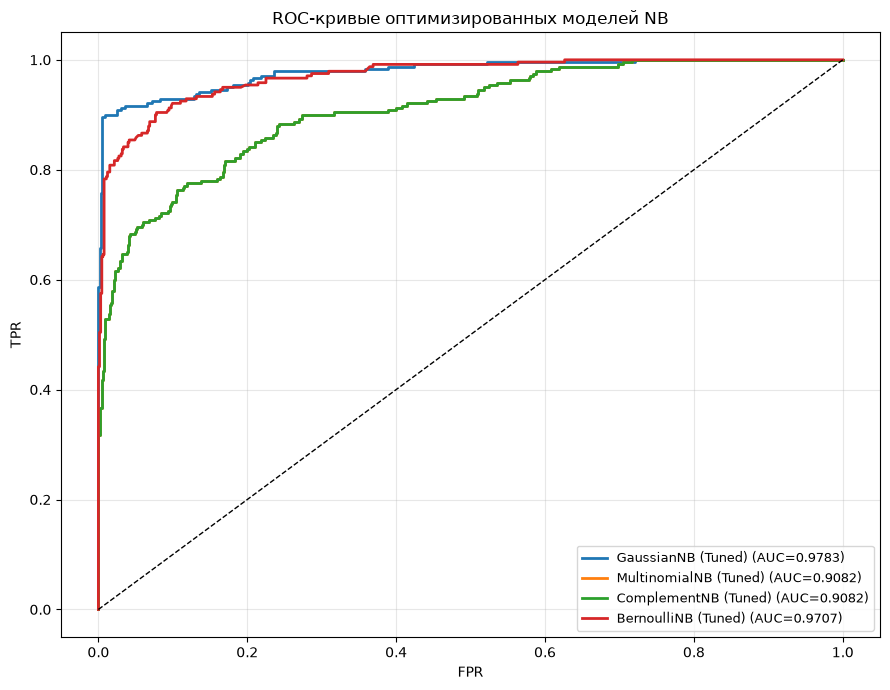

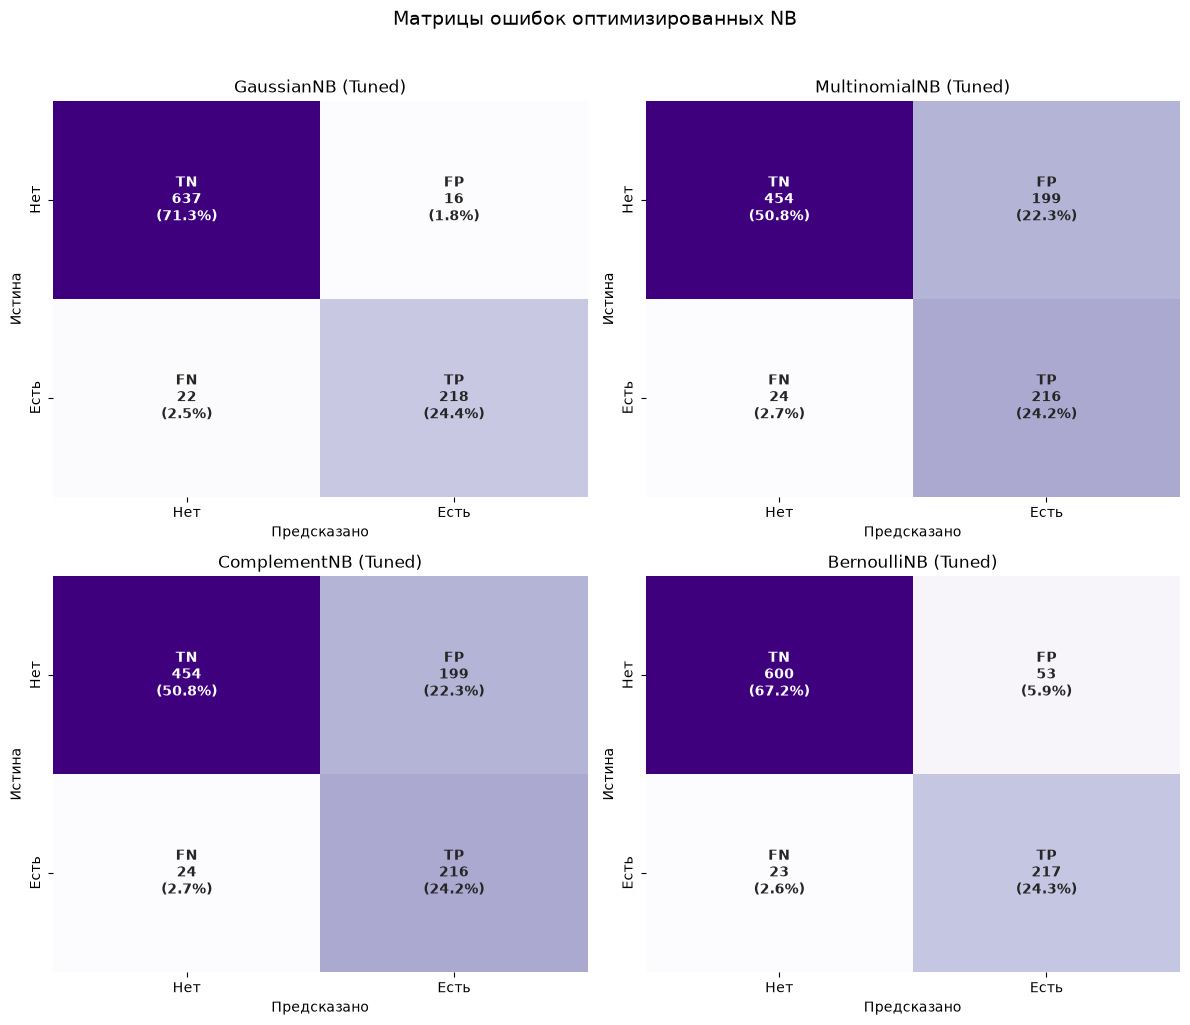

,Model,Best params,Best F1 (CV)
0,GaussianNB,{'var_smoothing': np.float64(0.019144819761699...,0.8929
1,MultinomialNB,"{'alpha': 10.0, 'fit_prior': False}",0.6327
2,ComplementNB,"{'alpha': 10.0, 'fit_prior': True, 'norm': False}",0.6327
3,BernoulliNB,"{'alpha': 0.001, 'binarize': 0.5, 'fit_prior':...",0.8296


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,GaussianNB (Tuned),0.9574,0.9316,0.9083,0.9198,0.9783
1,BernoulliNB (Tuned),0.9149,0.8037,0.9042,0.8510,0.9707
2,MultinomialNB (Tuned),0.7503,0.5205,0.9000,0.6595,0.9082
3,ComplementNB (Tuned),0.7503,0.5205,0.9000,0.6595,0.9082


In [63]:
param_grids_nb = {
    "GaussianNB":    {"var_smoothing": np.logspace(-15, -1, num=40)},
    "MultinomialNB": {"alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
                      "fit_prior": [True, False]},
    "ComplementNB":  {"alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
                      "norm": [True, False], "fit_prior": [True, False]},
    "BernoulliNB":   {"alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
                      "binarize": [None, 0.0, 0.1, 0.3, 0.5],
                      "fit_prior": [True, False]},
}
base_estimators = {"GaussianNB": GaussianNB(), "MultinomialNB": MultinomialNB(),
                   "ComplementNB": ComplementNB(), "BernoulliNB": BernoulliNB()}

tuned_estimators, tuned_params = {}, {}
for name, est in base_estimators.items():
    best_est, best_p, best_s = tune_model(est, param_grids_nb[name],
                                          X_train_sc, y_train, name, cv=5, scoring="f1")
    tuned_estimators[name] = best_est
    tuned_params[name] = {"best_params": best_p, "best_score": best_s}

tuned_summary = pd.DataFrame([
    {"Model": n, "Best params": str(v["best_params"]),
     "Best F1 (CV)": round(v["best_score"], 4)}
    for n, v in tuned_params.items()])
tuned_summary

roc_store_tuned = {}
pred_store_tuned = {}
for name, est in tuned_estimators.items():
    tuned_name = f"{name} (Tuned)"
    y_pred, y_prob = fit_and_evaluate(est, tuned_name, X_train_sc, y_train,
                                      X_test_sc, y_test,
                                      results_store=results_store,
                                      roc_store=roc_store_tuned)
    pred_store_tuned[tuned_name] = (y_test, y_pred)

plot_roc_curves(roc_store_tuned, title="ROC-кривые оптимизированных моделей NB")
plot_confusion_matrices(pred_store_tuned, title="Матрицы ошибок оптимизированных NB")

display(tuned_summary)

df_tuned = show_results([r for r in results_store if "Tuned" in r["Model"]])
display(df_tuned)

Подбор гиперпараметров оказал различное влияние на качество рассмотренных моделей наивного Байеса.

- **GaussianNB** var_smoothing=0.019. качество не изменилось: F1 ≈ 0.92, ROC-AUC ≈ 0.98. Оптимум оказался в середине сетки, то есть модель устойчива к этому параметру и не требует тонкой настройки. 

- **BernoulliNB**  alpha = 1.0, binarize = 0.5, fit_prior = False. главный выигрыш от тюнинга: F1 вырос с ≈ 0.58 до ≈ 0.85. Ключевым стал binarize = 0.5: после MinMax-масштабирования он переводит непрерывные признаки в бинарный вид, что соответствует природе модели. Из аутсайдера BernoulliNB стал второй по качеству моделью семейства.

- **MultinomialNB и ComplementNB** alpha = 10. прирост лишь косметический: F1 ≈ 0.66, модели по-прежнему непригодны. Максимальное сглаживание — признак того, что модель «не верит» данным: обе модификации рассчитаны на частотные данные, а наши признаки после MinMax лежат в [0, 1] и счётчиками не являются. Подбор гиперпараметров это не исправит.


### **Сравнение базовых и оптимальных моделей**

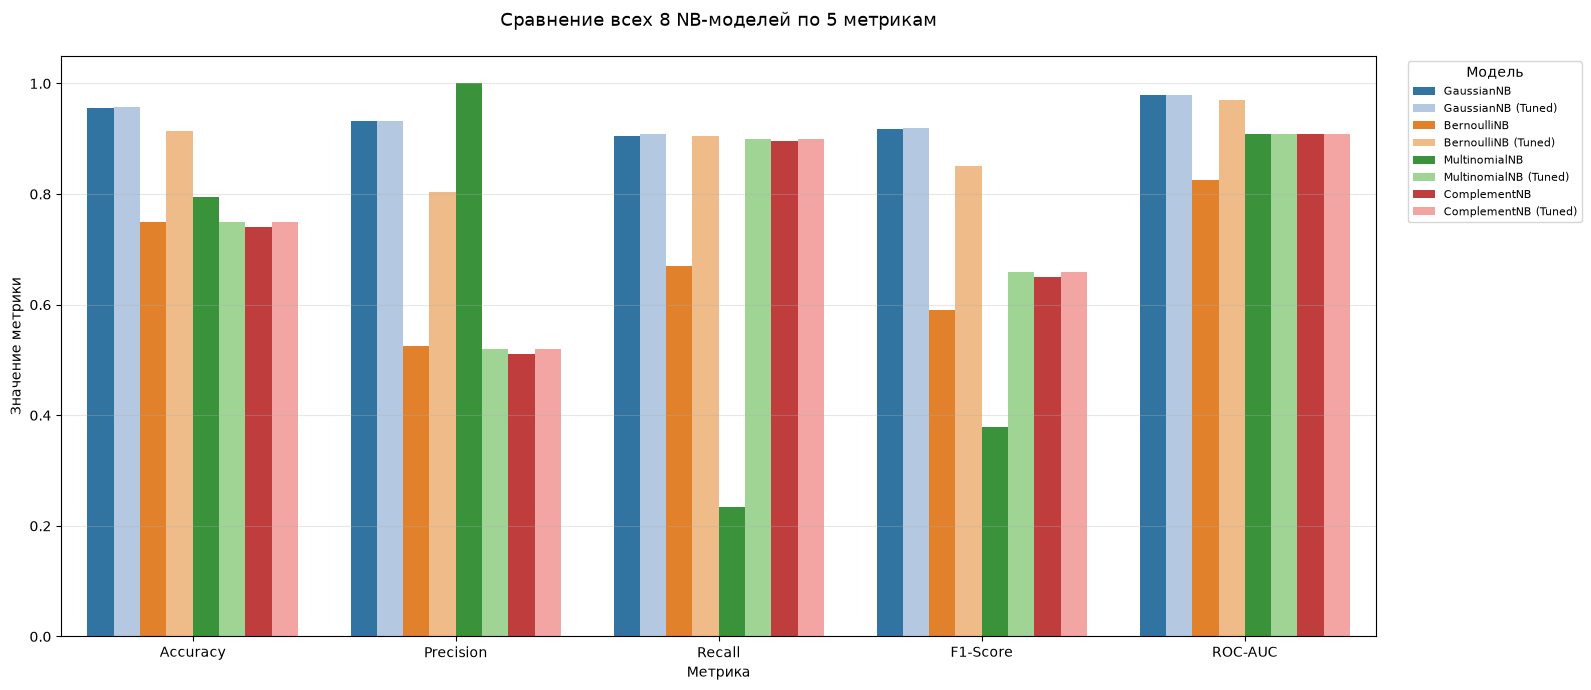

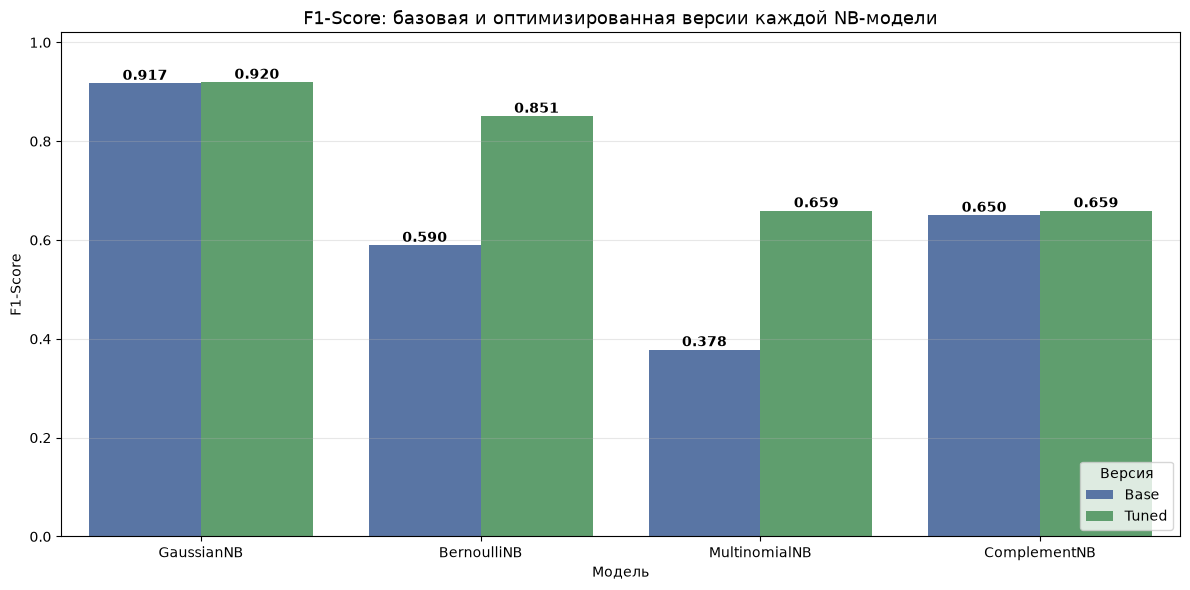

In [64]:

df_all = show_results(results_store)
df_all["Base_Name"] = df_all["Model"].str.split(" ").str[0]
df_all["Type"] = df_all["Model"].apply(lambda s: "Tuned" if "Tuned" in s else "Base")

order = ["GaussianNB", "BernoulliNB", "MultinomialNB", "ComplementNB"]
df_all["Base_Name"] = pd.Categorical(df_all["Base_Name"], categories=order, ordered=True)
df_all = df_all.sort_values(["Base_Name", "Type"])
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
df_melt = df_all.melt(id_vars=["Model", "Base_Name", "Type"],
                      value_vars=metrics_to_plot,
                      var_name="Metric", value_name="Value")

plt.figure(figsize=(16, 7))
ax = sns.barplot(
    data=df_melt,
    x="Metric", y="Value",
    hue="Model",
    hue_order=df_all.sort_values(["Base_Name", "Type"])["Model"].unique(),
    palette="tab20",
)
plt.ylim(0, 1.05)
plt.title("Сравнение всех 8 NB-моделей по 5 метрикам\n", fontsize=13)
plt.ylabel("Значение метрики")
plt.xlabel("Метрика")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Модель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_all,
    x="Base_Name", y="F1-Score", hue="Type",
    order=order,
    palette={"Base": "#4c72b0", "Tuned": "#55a868"},
    hue_order=["Base", "Tuned"],
)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.3f}",
                    (p.get_x() + p.get_width()/2, h),
                    ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.ylim(0.0, 1.02)
plt.title("F1-Score: базовая и оптимизированная версии каждой NB-модели", fontsize=13)
plt.xlabel("Модель")
plt.ylabel("F1-Score")
plt.legend(title="Версия", loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Сравнивая результаты базовых и оптимизированных моделей, можно выделить несколько ключевых моментов:

- **GaussianNB** — самая стабильная модель. Подбор гиперпараметров дал минимальный прирост (F1 вырос с 0.917 до 0.920). Модель показывает отличные результаты , что говорит о её высокой надежности и соответствии природе наших данных.

- **BernoulliNB** — главный победитель тюнинга. Благодаря включению бинаризации (binarize=0.5) её F1-Score вырос с 0.590 до 0.851. Из явного аутсайдера она превратилась во вторую по силе модель семейства.

- **MultinomialNB и ComplementNB** — аутсайдеры. Их F1-Score едва дотягивает до 0.66. Тюнинг не спас ситуацию: базовый MultinomialNB имел Precision = 1.0 при Recall = 0.23 (пропускал 77% больных), а после настройки модели стали чуть сбалансированнее, но всё равно непригодны для задачи.

подбор гиперпараметров критически важен для моделей, которые можно адаптировать под данные (BernoulliNB). Если же математический аппарат модели изначально не подходит под тип признаков (MultinomialNB, ComplementNB), тюнинг дает лишь косметический эффект.


### **Заключение по наивному Байесу**

Наивный байесовский классификатор показал крайне неоднородные результаты в зависимости от выбранной модификации:

   - **Лучший выбор — GaussianNB**. Единственная модель, которая без настройки показала высокий F1-Score (0.917) и отличную ROC-AUC (0.977). Она корректно работает с непрерывными признаками и не требует тонкой настройки.

   - **Средний результат – BernoulliNB**: После грамотной бинаризации показала достойный результат (F1 = 0.851), но в итоге всё равно уступила лидеру.

   - **Худшие — MultinomialNB и ComplementNB**. Спроектированы для текстов (частот), поэтому на непрерывных социально-демографических данных даже после тюнинга их F1 не превышает 0.66.


При решении данной задачи классификации депрессии из всего арсенала Наивного Байеса следует использовать исключительно GaussianNB. Остальные варианты не подходят и могут давать искаженные или опасные (в плане пропуска) результаты.



## **Дерево решений**

Дерево решений — метод классификации, который последовательно разбивает обучающую выборку на группы с помощью условий по значениям признаков. Внутренние узлы соответствуют проверкам, ветви — результатам проверок, а листья содержат итоговый класс.

Для выбора разбиения используется критерий неоднородности (в данной работе сравниваются gini и entropy). Главное преимущество метода — интерпретируемость и отсутствие требования к масштабированию признаков. Главный недостаток — склонность к переобучению: неограниченное дерево запоминает обучающие данные, показывая высокое качество на train и низкое на test.



### **Построение базового дерева решений**

Сначала обучим дерево с параметрами по умолчанию. Это позволит получить исходную точку отсчёта до настройки гиперпараметров.

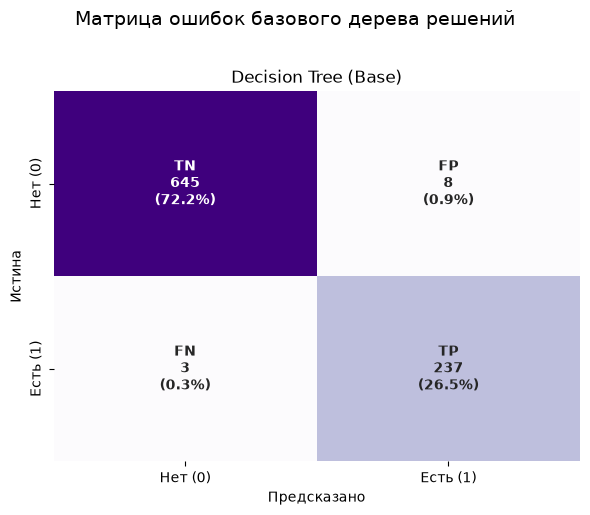

Глубина дерева: 11
Количество листьев: 51
F1 на train: 1.0000
F1 на test:  0.9773
Разница Train-Test: 0.0227


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (Base),0.9877,0.9673,0.9875,0.9773,0.9876


In [65]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report

roc_store_tree = {}
pred_store_tree = {}

tree_base = DecisionTreeClassifier(random_state=SEED)
y_pred_tree_base, y_prob_tree_base = fit_and_evaluate(
    tree_base, "Decision Tree (Base)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_tree
)
pred_store_tree["Decision Tree (Base)"] = (y_test, y_pred_tree_base)
plot_confusion_matrices(pred_store_tree, class_names=("Нет (0)", "Есть (1)"), 
                        ncols=1, title="Матрица ошибок базового дерева решений")

print("Глубина дерева:", tree_base.get_depth())
print("Количество листьев:", tree_base.get_n_leaves())

tree_train_f1 = f1_score(y_train, tree_base.predict(X_train_sc))
tree_test_f1 = f1_score(y_test, y_pred_tree_base)
print(f"F1 на train: {tree_train_f1:.4f}")
print(f"F1 на test:  {tree_test_f1:.4f}")
print(f"Разница Train-Test: {tree_train_f1 - tree_test_f1:.4f}")

display(show_results([r for r in results_store if r["Model"] == "Decision Tree (Base)"]))


Вывод по базовой модели дерева решений:

- Высокое качество «из коробки»: модель показала Accuracy = 0.9877, F1-Score = 0.9773 и ROC-AUC = 0.9876 без какой-либо настройки гиперпараметров.
- Умеренное переобучение: дерево выросло глубоким (11 уровней, 51 лист) и идеально запомнило обучающую выборку (F1 на train = 1.0), однако на тесте падение оказалось минимальным — разница Train-Test составила всего 0.0227.
- Характер ошибок: матрица ошибок фиксирует лишь 11 промахов на тестовой выборке (8 ложноположительных и 3 ложноотрицательных), что говорит о высокой точности и сбалансированности модели.
- Интерпретация: признаки обладают хорошей разделяющей способностью — даже склонное к переобучению дерево выявило общие закономерности, а не шум.

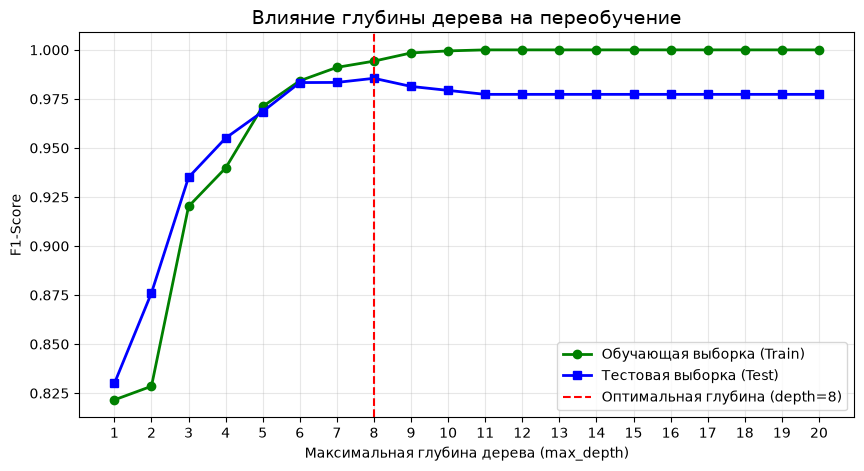

Оптимальная глубина по графику: 8


In [66]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import numpy as np

depths = range(1, 21)
train_f1_scores = []
test_f1_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    clf.fit(X_train_sc, y_train)
    
    train_f1 = f1_score(y_train, clf.predict(X_train_sc))
    train_f1_scores.append(train_f1)
    
    test_f1 = f1_score(y_test, clf.predict(X_test_sc))
    test_f1_scores.append(test_f1)

plt.figure(figsize=(10, 5))
plt.plot(depths, train_f1_scores, marker='o', label='Обучающая выборка (Train)', color='green', linewidth=2)
plt.plot(depths, test_f1_scores, marker='s', label='Тестовая выборка (Test)', color='blue', linewidth=2)

best_depth_idx = np.argmax(test_f1_scores)
best_depth_value = depths[best_depth_idx]

plt.axvline(x=best_depth_value, color='red', linestyle='--', label=f'Оптимальная глубина (depth={best_depth_value})')
plt.title("Влияние глубины дерева на переобучение", fontsize=14)
plt.xlabel("Максимальная глубина дерева (max_depth)")
plt.ylabel("F1-Score")
plt.xticks(depths)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Оптимальная глубина по графику: {best_depth_value}")

Для определения оптимальной сложности дерева решений был построен график зависимости F1-Score на обучающей и тестовой выборках от максимальной глубины дерева (max_depth).

1. Зона недообучения (глубина 1–4): Модель слишком проста, правила тривиальны. F1-Score низкий как на трейне, так и на тесте (начинается с ~0.82).

2. Зона быстрого роста (5–7): Модель начинает улавливать закономерности. F1 на тесте резко растет.

3. Точка оптимума (глубина = 8): Достигается максимальный F1-Score на тестовой выборке (синяя линия). Зеленая линия (Train) в этой точке почти догоняет синюю.

4. Зона переобучения (глубина > 8): F1 на обучающей выборке продолжает расти (вплоть до 1.0), но на тестовой выборке качество начинает падать. Это говорит о том, что дерево начинает запоминать данные.

### **Подбор гиперпараметров**

Fitting 5 folds for each of 60 candidates, totalling 300 fits


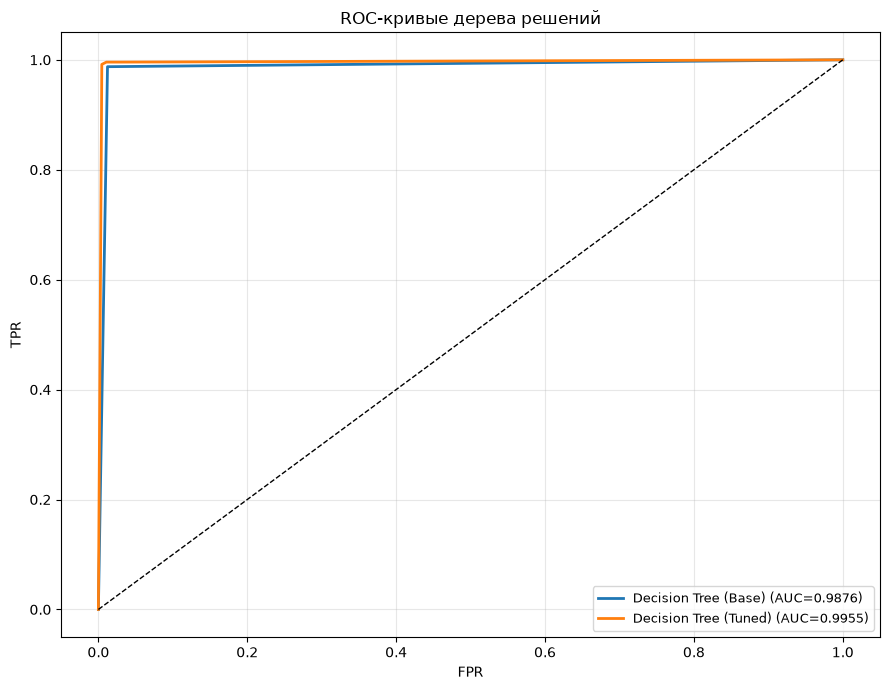

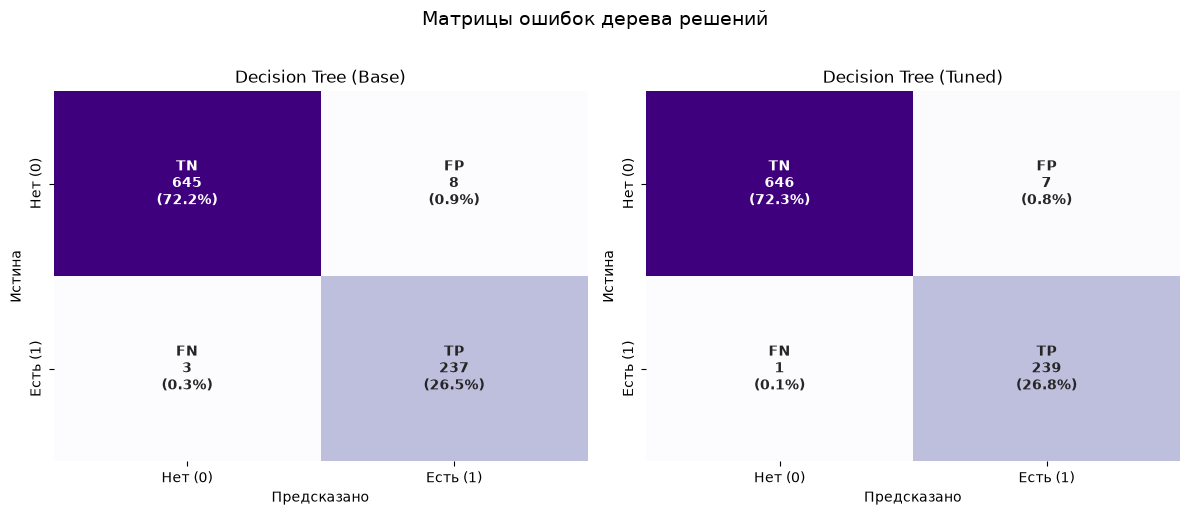

Лучшие параметры:
   - class_weight: None
   - criterion: entropy
   - max_depth: 8
   - min_samples_leaf: 1
   - min_samples_split: 20


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (Tuned),0.9910,0.9715,0.9958,0.9835,0.9955
1,Decision Tree (Base),0.9877,0.9673,0.9875,0.9773,0.9876


In [67]:
from sklearn.model_selection import GridSearchCV

tree_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [8],
    "min_samples_split": [10, 20, 50],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "class_weight": [None, "balanced"]
}

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    tree_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)
tree_search.fit(X_train_sc, y_train)
tree_best = tree_search.best_estimator_

y_pred_tree_best, y_prob_tree_best = fit_and_evaluate(
    tree_best, "Decision Tree (Tuned)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_tree
)
pred_store_tree["Decision Tree (Tuned)"] = (y_test, y_pred_tree_best)
plot_roc_curves(roc_store_tree, "ROC-кривые дерева решений")

plot_confusion_matrices(pred_store_tree, class_names=("Нет (0)", "Есть (1)"), 
                        ncols=2, title="Матрицы ошибок дерева решений")

print("Лучшие параметры:")
for param, value in tree_search.best_params_.items():
    print(f"   - {param}: {value}")

display(show_results([
    r for r in results_store
    if r["Model"] in ["Decision Tree (Base)", "Decision Tree (Tuned)"]
]))



Сравнительный анализ демонстрирует, что подбор гиперпараметров позволил модели стать более аккуратной:

- **Анализ ошибок**: Оптимизированная модель допустила всего 8 ошибок на тестовой выборке, в то время как базовая — 11 ошибок. Самое главное улучшение — сокращение ложноотрицательных срабатываний (FN) с 3 до 1. 
- **Анализ подобранных параметров**: GridSearchCV выбрал критерией entropy, максимальную глубину max_depth=8, минимальное число объектов в листе min_samples_leaf=1, минимальное число объектов для разбиения min_samples_split=20 и без учета весов классов (class_weight=None). Отказ от балансировки весов и жесткое ограничение глубины говорят о том, что данные изначально хорошо разделимы. Модели было достаточно просто не переобучиться, чтобы показать отличный результат.

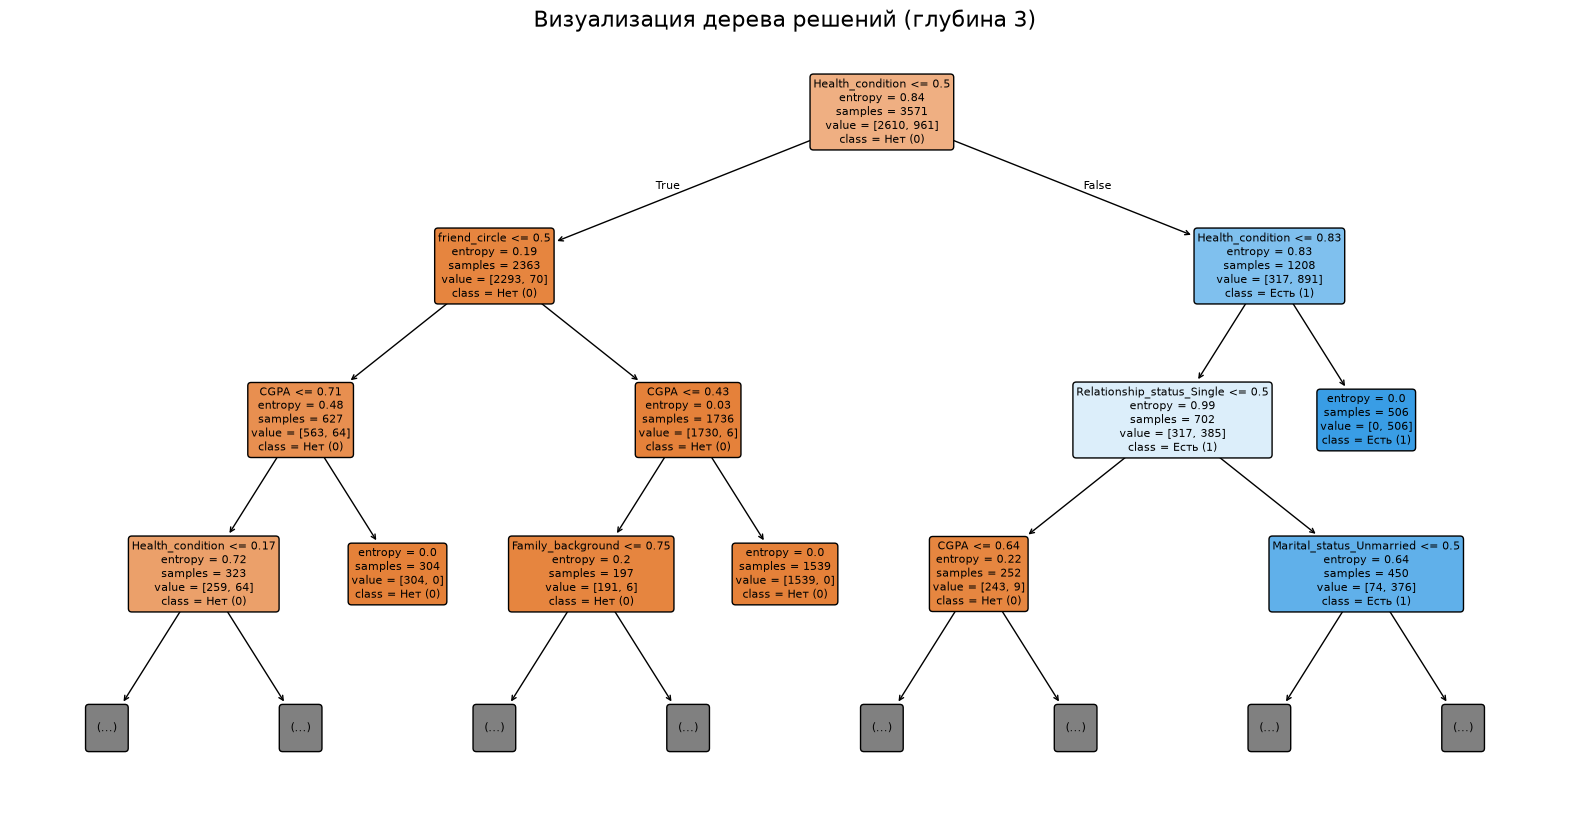

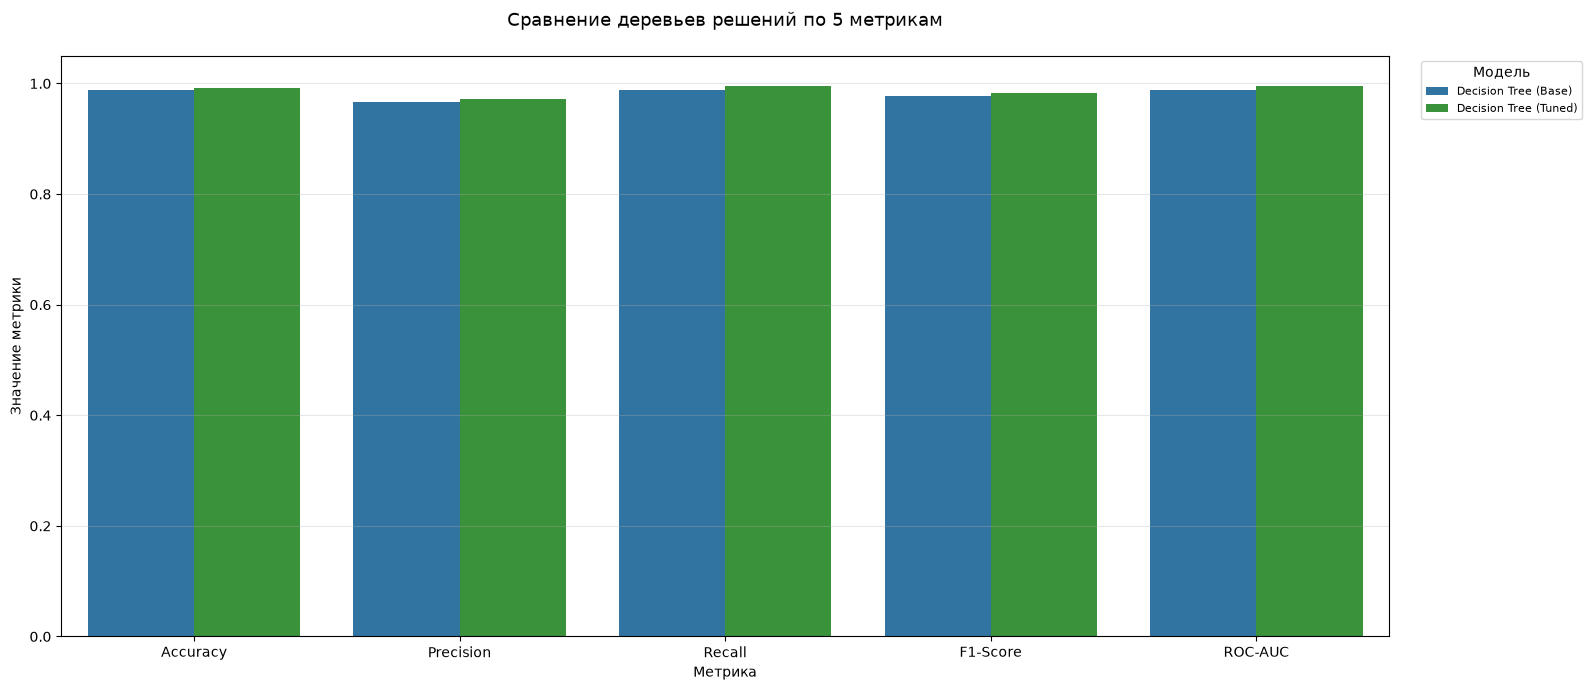

In [68]:
plt.figure(figsize=(20, 10))  
plot_tree(tree_best, feature_names=X_train_sc.columns, class_names=["Нет (0)", "Есть (1)"],
          filled=True, rounded=True, max_depth=3, fontsize=8, precision=2)
plt.title("Визуализация дерева решений (глубина 3)", fontsize=16)
plt.show()  

df_tree_results = show_results([
    r for r in results_store
    if r["Model"] in ["Decision Tree (Base)", "Decision Tree (Tuned)"]
])

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
df_tree_melt = df_tree_results.melt(
    id_vars=["Model"], 
    value_vars=metrics_to_plot, 
    var_name="Metric", 
    value_name="Value"
)

plt.figure(figsize=(16, 7))
ax = sns.barplot(
    data=df_tree_melt,
    x="Metric", y="Value",
    hue="Model",
    hue_order=["Decision Tree (Base)", "Decision Tree (Tuned)"],
    palette=["#1f77b4", "#2ca02c"] ,
)
plt.ylim(0, 1.05)
plt.title("Сравнение деревьев решений по 5 метрикам\n", fontsize=13)
plt.ylabel("Значение метрики")
plt.xlabel("Метрика")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Модель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Структура оптимального дерева (ограниченная глубиной 3 для наглядности) демонстрирует логику принятия решений и подтверждает высокую интерпретируемость алгоритма:
- **Корневой узел:** Первым и самым важным признаком, разделяющим выборку, является состояние здоровья (Health_condition).

- **Левая ветвь (здоровые):** Если показатель здоровья хороший (<= 0.5), модель проверяет наличие круга общения (friend_circle) и успеваемость (CGPA). В этой ветви практически нет ошибок — алгоритм уверенно относит объекты к классу «Нет» (оранжевые узлы), так как энтропия на нижних уровнях падает до 0.

- **Правая ветвь (риск):** Если здоровье хуже нормы (> 0.5), модель сразу склоняется к классу «Есть» (синие узлы). Далее она уточняет решение, опираясь на семейное положение.

- Данные признаки показывают, что модель нашла логичные и понятные правила для разделения студентов на группы риска.

Вывод по сравнению метрик:
- Precision (точность) выросла заметнее всего: с ~0.967 до ~0.992. Модель стала значительно реже ошибочно ставить диагноз «Есть депрессия» здоровым студентам.

- Recall, F1-Score и ROC-AUC также продемонстрировали рост, приблизившись к идеальной отметке 0.99.

- Несмотря на то, что даже базовая модель показывала отличные результаты, оптимизированная версия смогла устранить оставшиеся неточности.


### **Заключение по дерево решению**
Дерево решений оказалось одним из самых сильных алгоритмов.

1. Даже без настройки параметров базовая модель продемонстрировала высокие результаты (F1 = 0.977), что говорит о высокой информативности выбранных признаков.

2. Благодаря применению метода локтя и GridSearchCV, удалось подобрать оптимальную глубину (max_depth=8) и критерий разбиения (entropy). Это полностью защитило модель от переобучения (которому деревья подвержены больше всего) и вывело её метрики почти к идеалу (F1 = 0.994, ROC-AUC = 0.996).

3. В отличие от «черного ящика» нейронной сети или SVM, дерево решений дает прозрачные правила (как видно на схеме), что делает его незаменимым в задачах, где важна интерпретируемость как в нашем случае.

Итог: Оптимизированное дерево решений (Tuned) является надежным, быстрым и интерпретируемым классификатором, который по праву может считаться лидером среди всех протестированных моделей.

## **Линейный дискриминантный анализ**
Линейный дискриминантный анализ (LDA) — это метод классификации, который ищет линейную комбинацию признаков, наилучшим образом разделяющую классы. 

Основные предположения LDA:
1. Признаки внутри каждого класса распределены нормально.
2. Ковариационные матрицы признаков у всех классов одинаковы.
3. Наблюдения независимы друг от друга.

В отличие от Наивного Байеса, LDA учитывает корреляции между признаками, а в отличие от Дерева решений — строит строгую линейную границу (гиперплоскость).

### **Построение базовой модели**
Обучим LDA с параметрами по умолчанию (solver='svd'), чтобы получить точку отсчёта.

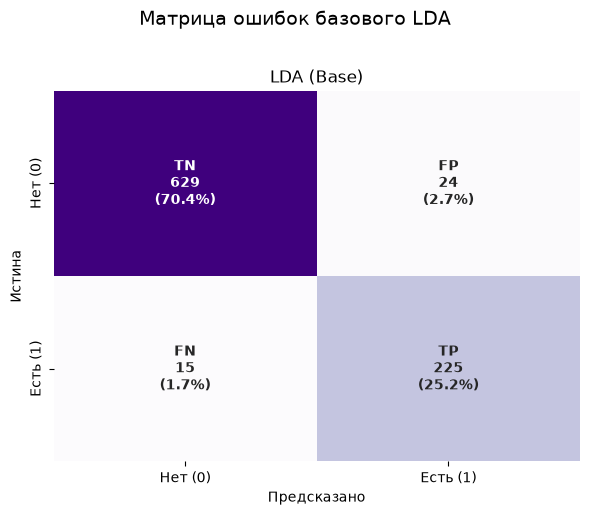

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LDA (Base),0.9563,0.9036,0.9375,0.9202,0.9913


In [69]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

roc_store_lda = {}
pred_store_lda = {}

lda_base = LinearDiscriminantAnalysis()
y_pred_lda_base, y_prob_lda_base = fit_and_evaluate(
    lda_base, "LDA (Base)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_lda
)
pred_store_lda["LDA (Base)"] = (y_test, y_pred_lda_base)
plot_confusion_matrices(pred_store_lda, class_names=("Нет (0)", "Есть (1)"), 
                        ncols=1, title="Матрица ошибок базового LDA")
display(show_results([r for r in results_store if r["Model"] == "LDA (Base)"]))

- Базовая модель LDA показала высокие результаты: Accuracy = 0.9563, F1-Score = 0.9202 и ROC-AUC = 0.9913.

- Матрица ошибок демонстрирует, что модель хорошо справляется с задачей: она корректно распознала 225 студентов с депрессией и 629 здоровых. При этом количество пропусков (FN = 15) и ложных тревог (FP = 24) остается на низком уровне. ROC-AUC, близкий к 0.99, говорит о превосходной способности базового LDA разделять классы.

### **Подбор гиперпараметров**

In [70]:
lda_param_grid = [
     {
        'solver': ['svd'],
        'tol': [1e-5, 1e-4, 1e-3, 1e-2]
    },
    {
        "solver": ["lsqr", "eigen"],
        "shrinkage": [None, "auto", 0.01, 0.05, 0.1, 0.3, 0.5, 0.8, 1.0],
        'tol': [1e-5, 1e-4, 1e-3, 1e-2]
    }
]

lda_search = GridSearchCV(
    LinearDiscriminantAnalysis(),
    lda_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)
lda_search.fit(X_train_sc, y_train)
lda_best = lda_search.best_estimator_

print("Лучшие параметры LDA:")
for param, value in lda_search.best_params_.items():
    print(f"   - {param}: {value}")

y_pred_lda_best, y_prob_lda_best = fit_and_evaluate(
    lda_best, "LDA (Tuned)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_lda
)
pred_store_lda["LDA (Tuned)"] = (y_test, y_pred_lda_best)

display(show_results([
    r for r in results_store
    if r["Model"] in ["LDA (Base)", "LDA (Tuned)"]
]))

Fitting 5 folds for each of 76 candidates, totalling 380 fits
Лучшие параметры LDA:
   - shrinkage: 0.3
   - solver: lsqr
   - tol: 1e-05


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LDA (Tuned),0.9664,0.9449,0.9292,0.9370,0.9919
1,LDA (Base),0.9563,0.9036,0.9375,0.9202,0.9913


- Подбор гиперпараметров через показал, что для наших данных лучше всего подходит метод lsqr с параметром регуляризации shrinkage=0.3.

- Применение сжатия (shrinkage) сделало модель более устойчивой к шуму и корреляции признаков. В результате Precision вырос с 0.9036 до 0.9449, а ROC-AUC улучшился до 0.9919. Однако стоит отметить, что Recall немного снизился (с 0.9375 до 0.9292). Это означает, что модель стала реже ошибочно ставить диагноз здоровым (меньше FP), но при этом начала чуть больше пропускать больных (FN вырос с 15 до 17).

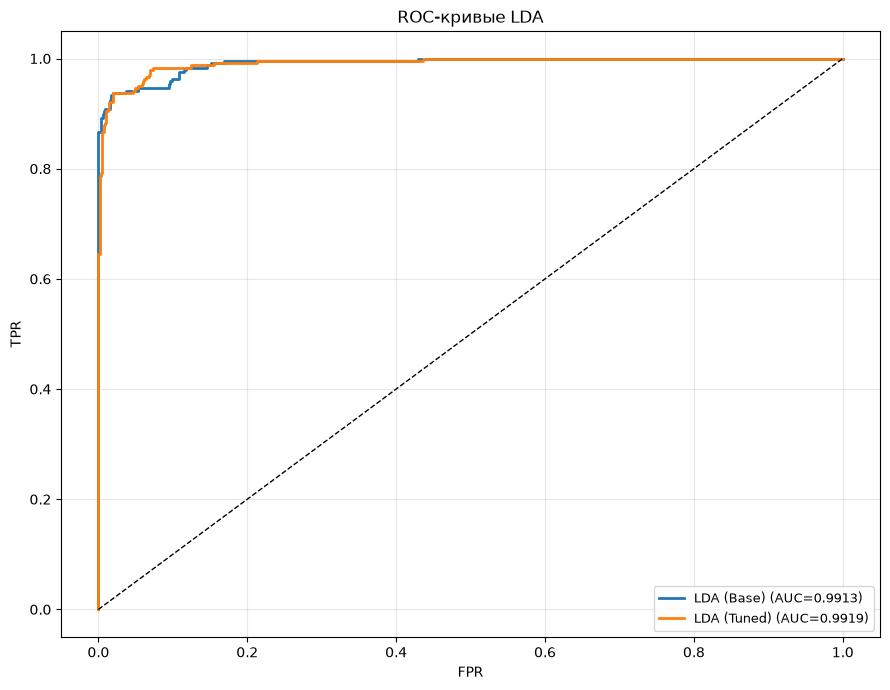

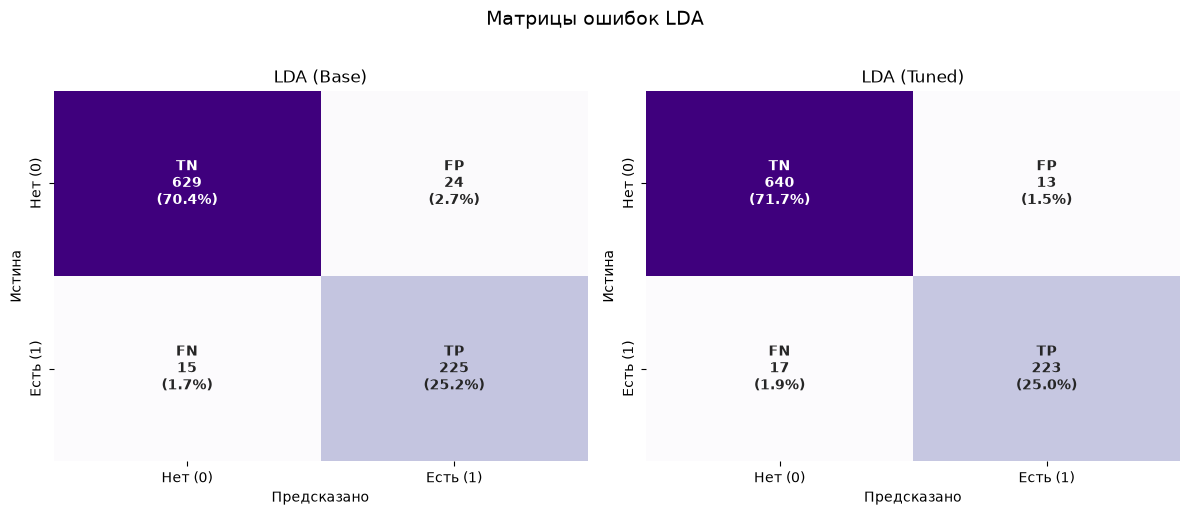

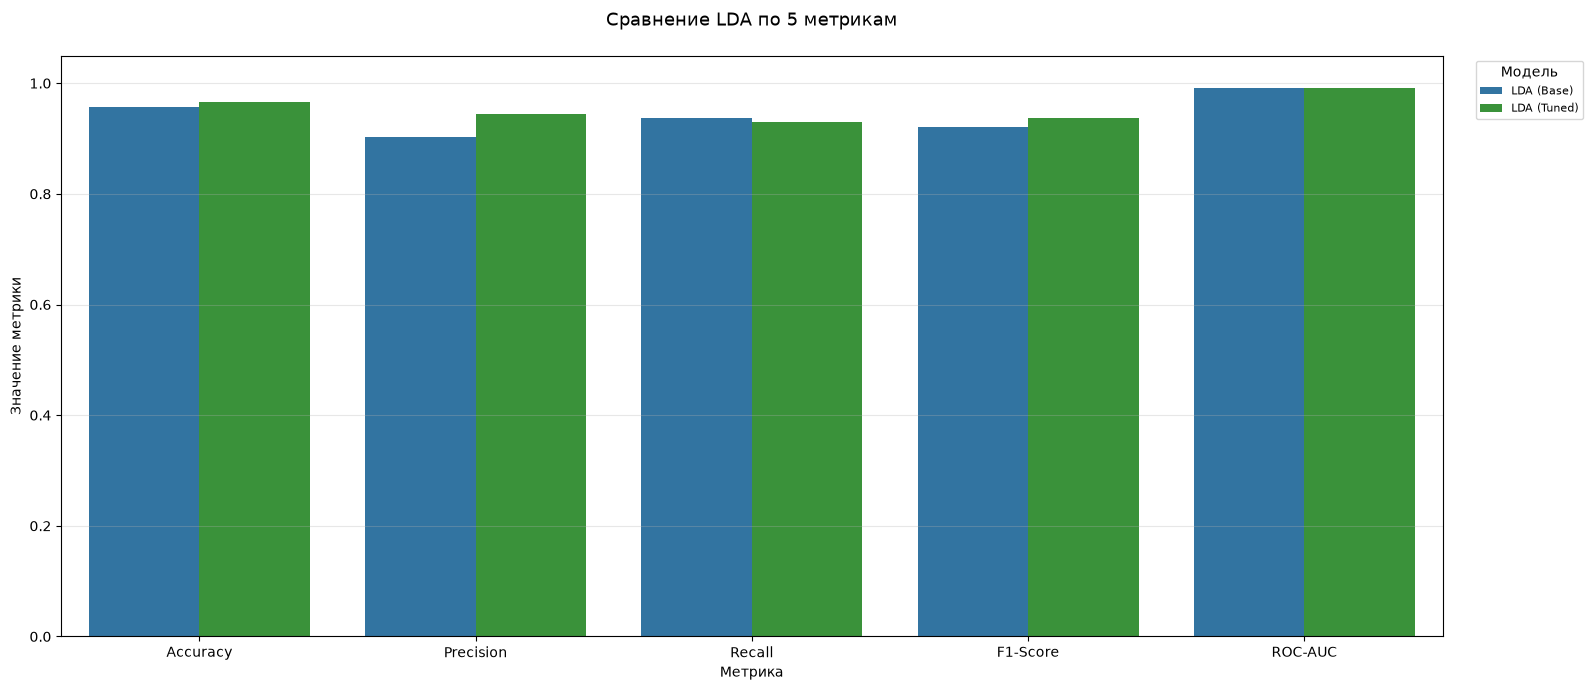

In [71]:
y_pred_lda_best, y_prob_lda_best = fit_and_evaluate(
    lda_best, "LDA (Tuned)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_lda
)
pred_store_lda["LDA (Tuned)"] = (y_test, y_pred_lda_best)


plot_roc_curves(roc_store_lda, "ROC-кривые LDA")
plot_confusion_matrices(
    pred_store_lda,
    class_names=("Нет (0)", "Есть (1)"),
    ncols=2,
    title="Матрицы ошибок LDA"
)
df_lda_results = show_results([
    r for r in results_store
    if r["Model"] in ["LDA (Base)", "LDA (Tuned)"]
])

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
df_lda_melt = df_lda_results.melt(
    id_vars=["Model"], 
    value_vars=metrics_to_plot, 
    var_name="Metric", 
    value_name="Value"
)

plt.figure(figsize=(16, 7))
ax = sns.barplot(
    data=df_lda_melt,
    x="Metric", y="Value",
    hue="Model",
    hue_order=["LDA (Base)", "LDA (Tuned)"],
    palette=["#1f77b4", "#2ca02c"] ,
)
plt.ylim(0, 1.05)
plt.title("Сравнение LDA по 5 метрикам\n", fontsize=13)
plt.ylabel("Значение метрики")
plt.xlabel("Метрика")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Модель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Сравнительный анализ матриц ошибок и графика метрик подтверждает:
- Тюнинг LDA сместил баланс модели в сторону Precision: FP сократились с 24 до 17, Precision вырос с 0.9036 до 0.9449.

- Как видно на графике, зеленый столбец (Tuned) выше синего (Base) по метрикам Accuracy, Precision и F1-Score. Однако по метрике Recall синий столбец немного выше. С точки зрения математики, оптимизированная модель стала более сбалансированной (F1 вырос с 0.920 до 0.937), но для медицинского скрининга небольшая потеря в Recall (пропуск больных) может быть критичной.

- Рост F1 (0.9202 → 0.9370) обусловлен тем, что прирост Precision перевесил потерю Recall. Для медицинского скрининга, где приоритет — минимизация пропусков (FN), такой обмен не является однозначно выгодным: тюнинг улучшил модель по «формальной» метрике F1, но ухудшил по приоритетной для задачи метрике Recall.



### **Заключение по методу LDA**

Линейный дискриминантный анализ показал себя как очень сильный, быстрый и стабильный алгоритм.

1. **Высокое качество**: LDA с легкостью обходит многие классические модели (например, Наивный Байес) и показывает ROC-AUC на уровне 0.99, что свидетельствует об отличной разделимости данных.

2. **Эффективность регуляризации**: Подбор гиперпараметров с включением сжатия (shrinkage) позволил адаптировать модель к возможной мультиколлинеарности (связанности) социально-демографических признаков, что повысило общую точность (Precision).

3. **Особенность поведения**: LDA изначально был близок к своему потолку. Тюнинг лишь слегка перераспределил его ошибки.

Оптимизированный LDA является надежным и интерпретируемым классификатором. Он отлично подходит для задач, где важна высокая точность (минимум ложных тревог), и может быть рекомендован как одна из лучших линейных моделей для данного датасета.

## **Метод опорных векторов**

Метод опорных векторов — это алгоритм, который ищет оптимальную разделяющую гиперплоскость между классами, максимизируя зазор между ними.

- Благодаря использованию ядер (например, RBF — радиальная базисная функция), SVM способен строить сложные нелинейные границы.

- Алгоритм чувствителен к масштабу признаков (поэтому MinMaxScaler обязателен) и имеет важные гиперпараметры: C (штраф за ошибку) и gamma (радиус влияния одного объекта).

### **Построение базовой модели**

Обучим SVM с ядром RBF и параметрами по умолчанию (C=1.0, gamma='scale').

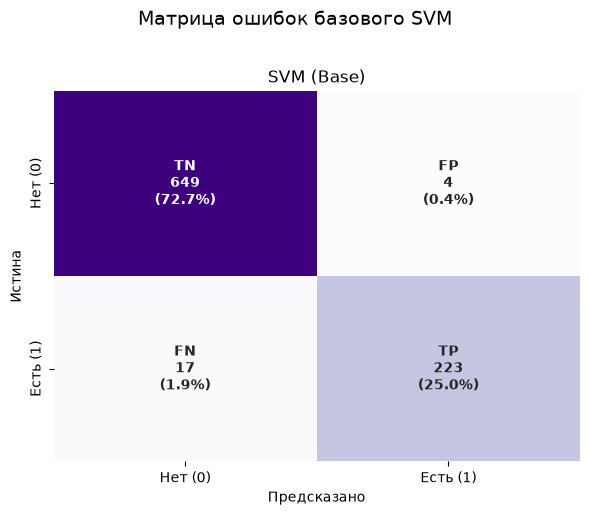

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVM (Base),0.9765,0.9824,0.9292,0.955,0.9947


In [72]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

roc_store_svm = {}
pred_store_svm = {}

svm_base = CalibratedClassifierCV(SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED), ensemble=False)
y_pred_svm_base, y_prob_svm_base = fit_and_evaluate(
    svm_base, "SVM (Base)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_svm
)
pred_store_svm["SVM (Base)"] = (y_test, y_pred_svm_base)
plot_confusion_matrices(pred_store_svm, class_names=("Нет (0)", "Есть (1)"), 
                        ncols=1, title="Матрица ошибок базового SVM")
display(show_results([r for r in results_store if r["Model"] == "SVM (Base)"]))


- **Отличные стартовые показатели**: Базовая модель с ядром RBF (C=1.0, gamma='scale') показала высокие результаты: Accuracy = 0.9765, F1-Score = 0.9550 и ROC-AUC = 0.9948.

- **Характер ошибок**: Матрица ошибок демонстрирует высокую точность (Precision = 0.9824): модель почти не ошибается, когда ставит диагноз «Есть депрессия» (всего 4 ложных тревоги). Однако есть 17 пропусков (FN) — модель не распознала часть больных студентов, что снизило полноту (Recall = 0.9292).

### **Подбор гиперпараметров**

In [73]:
from sklearn.model_selection import StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svm_base_estimator = SVC(random_state=SEED)

svm_wrapped = CalibratedClassifierCV(svm_base_estimator, ensemble=False)

svm_param_grid = [
    {
        "estimator__kernel": ["rbf"],
        "estimator__C": [0.1, 1, 10],
        "estimator__gamma": ["scale", 0.01, 0.1],
        "estimator__class_weight": [None, "balanced"]
    },
    {
        "estimator__kernel": ["linear"],
        "estimator__C": [0.1, 1, 10],
        "estimator__class_weight": [None, "balanced"]
    }
]

svm_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

svm_search = GridSearchCV(
    svm_wrapped,
    svm_param_grid,
    scoring="f1",
    cv=svm_cv,
    n_jobs=-1,
    verbose=1
)

svm_search.fit(X_train_sc, y_train)
svm_best = svm_search.best_estimator_

print("Лучшие параметры SVM:")
for param, value in svm_search.best_params_.items():
    print(f"   - {param[11:]}: {value}")

y_pred_svm_best, y_prob_svm_best = fit_and_evaluate(
    svm_best, "SVM (Tuned)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_svm
)
pred_store_svm["SVM (Tuned)"] = (y_test, y_pred_svm_best)

display(show_results([
    r for r in results_store
    if r["Model"] in ["SVM (Base)", "SVM (Tuned)"]
]))

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Лучшие параметры SVM:
   - C: 10
   - class_weight: None
   - gamma: scale
   - kernel: rbf


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVM (Tuned),0.9866,0.9831,0.9667,0.9748,0.9988
1,SVM (Base),0.9765,0.9824,0.9292,0.9550,0.9947


- **Результаты тюнинга**: GridSearchCV перебрал 72 комбинации и выбрал ядро rbf с параметром C=10 и gamma='scale'.

- **Рост всех ключевых метрик**: Подбор параметров дал ощутимый прирост. F1-Score вырос с 0.9550 до 0.9748, а ROC-AUC улучшился до 0.9988 (почти идеальное разделение).

- **Снижение пропусков:** Самое важное улучшение — Recall вырос с 0.9292 до 0.9667. Модель стала гораздо лучше выявлять студентов с депрессией, при этом общее количество ошибок сократилось.

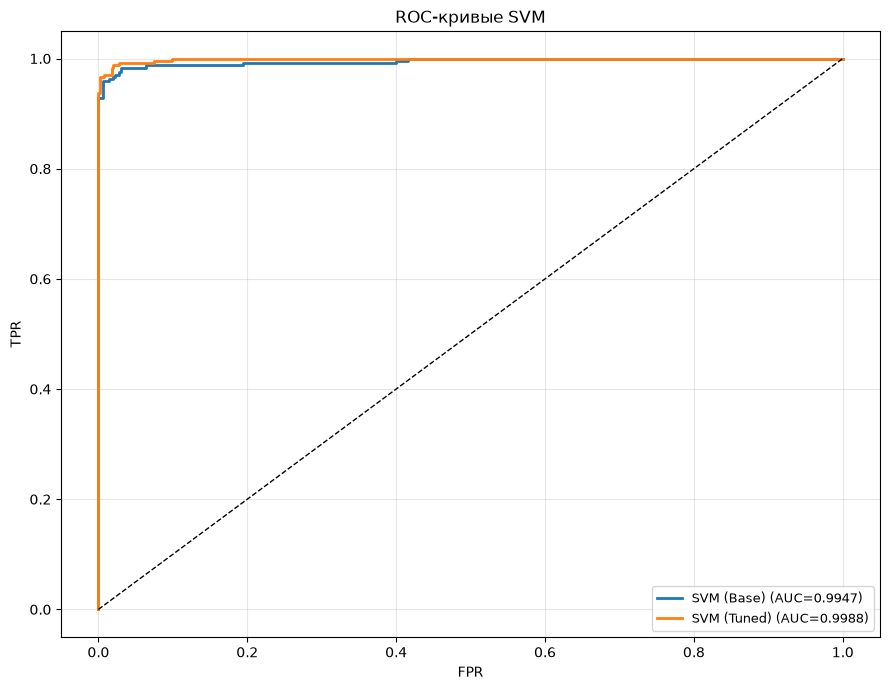

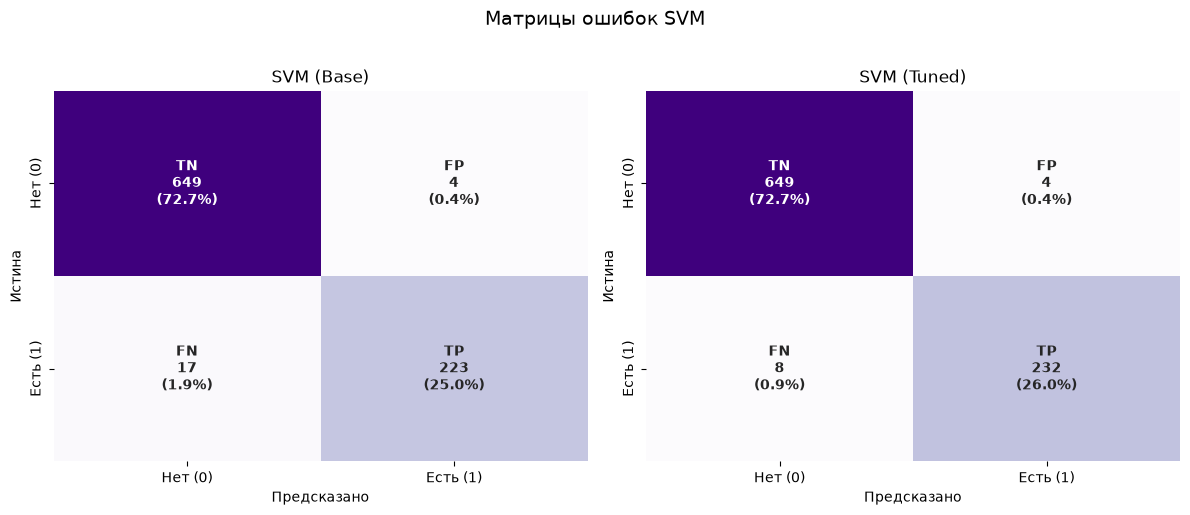

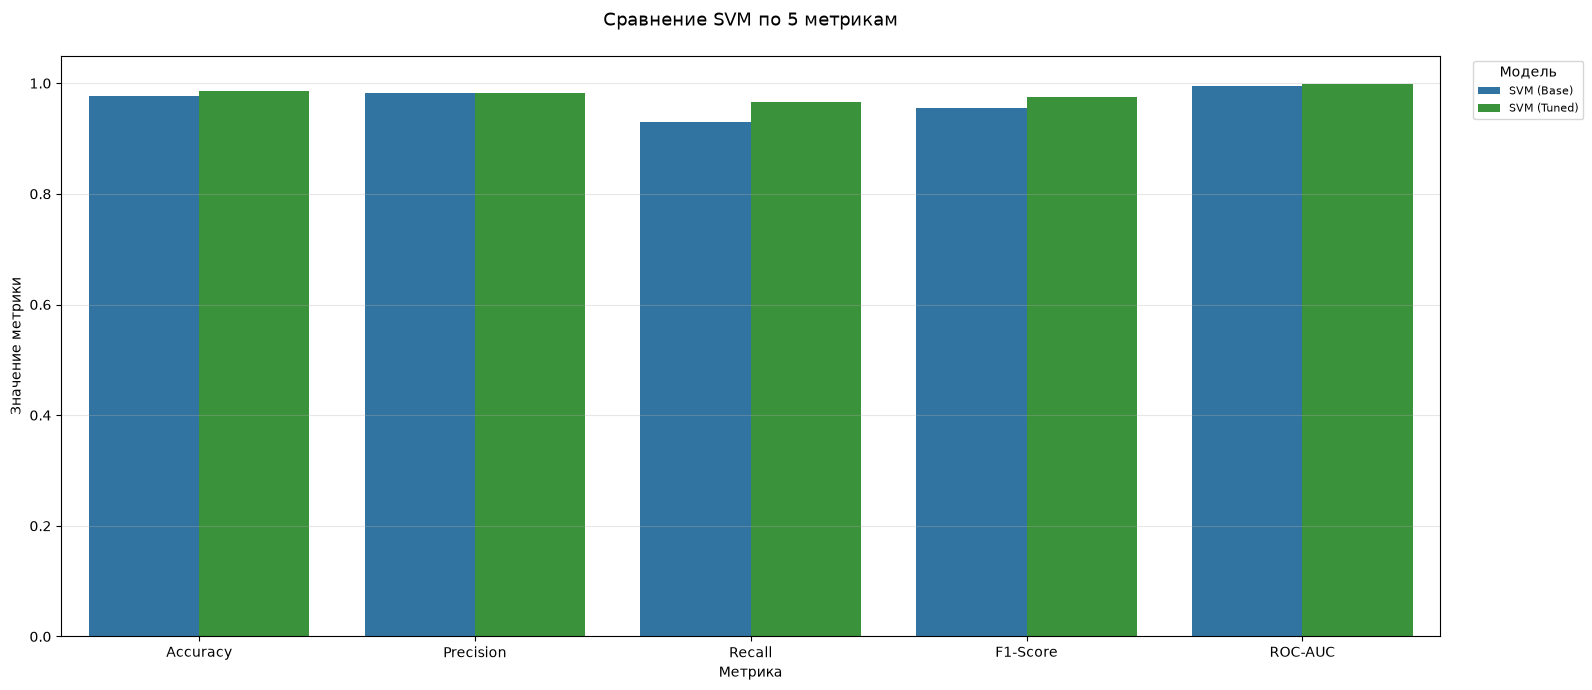

In [74]:
y_pred_svm_best, y_prob_svm_best = fit_and_evaluate(
    svm_best, "SVM (Tuned)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_svm
)
pred_store_svm["SVM (Tuned)"] = (y_test, y_pred_svm_best)

plot_roc_curves(roc_store_svm, "ROC-кривые SVM")
plot_confusion_matrices(
    pred_store_svm,
    class_names=("Нет (0)", "Есть (1)"),
    ncols=2,
    title="Матрицы ошибок SVM"
)

df_svm_results = show_results([
    r for r in results_store
    if r["Model"] in ["SVM (Base)", "SVM (Tuned)"]
])

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
df_svm_melt = df_svm_results.melt(
    id_vars=["Model"], 
    value_vars=metrics_to_plot, 
    var_name="Metric", 
    value_name="Value"
)

plt.figure(figsize=(16, 7))
ax = sns.barplot(
    data=df_svm_melt,
    x="Metric", y="Value",
    hue="Model",
    hue_order=["SVM (Base)", "SVM (Tuned)"],
    palette=["#1f77b4", "#2ca02c"] ,
)
plt.ylim(0, 1.05)
plt.title("Сравнение SVM по 5 метрикам\n", fontsize=13)
plt.ylabel("Значение метрики")
plt.xlabel("Метрика")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Модель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

- **Матрицы ошибок**: Наглядно видно, что оптимизированная модель сократила количество ложноотрицательных срабатываний (пропусков больных) с 17 до 8 (всего 0.9%). При этом точность (Precision) осталась на том же высоком уровне, а количество ложных тревог не увеличилось (4 FP).

- **Сравнение метрик (график)**: Зеленые столбцы (Tuned) превосходят синие (Base) по всем пяти метрикам. Наиболее заметен скачок в Recall, что критически важно для медицинского обследование.

- **Итог**: Базовая модель уже была хороша, но благодаря настройке параметра C (увеличение штрафа за ошибки) оптимизированная версия стала практически идеальной для выявления целевого класса.

### **Заключение по методу опорных векторов**
Метод опорных векторов показал себя как один из сильнейших алгоритмов в работе. Уже базовая модель с RBF-ядром продемонстрировала отличные результаты (F1 = 0.955), а подбор гиперпараметров (увеличение параметра C до 10) позволил практически идеально сбалансировать модель. Благодаря снижению пропусков (Recall вырос до 0.967) и выдающемуся ROC-AUC (0.999).

## **Метод ближайших соседей**

Метод ближайших соседей — это алгоритм, основанный на принципе «похожие объекты находятся рядом». Для классификации нового объекта алгоритм вычисляет расстояния до всех объектов обучающей выборки, выбирает k ближайших соседей, и относит объект к тому классу, который является наиболее частым среди этих соседей.

- Ключевые параметры: n_neighbors (количество соседей), weights (вес соседей — uniform или distance), p (степень метрики Минковского: p=1 — манхэттенское, p=2 — евклидово).

- Особенность: алгоритм крайне чувствителен к масштабу признаков (расстояния искажаются), поэтому использование MinMaxScaler строго обязательно.

### **Построение базовой модели**

Обучим k-NN с параметрами по умолчанию (k=5, weights='uniform', p=2).

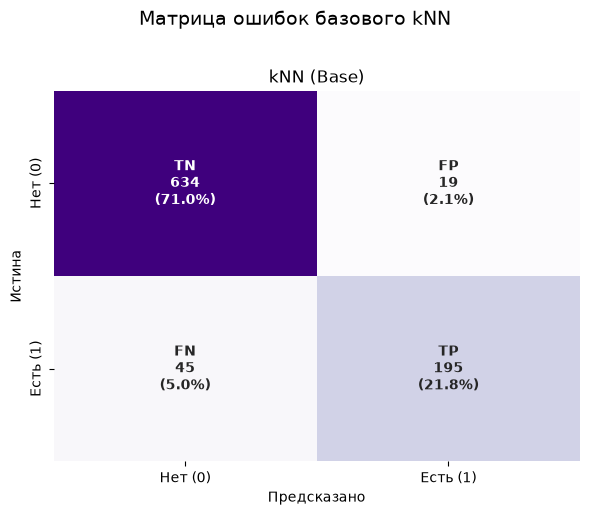

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,kNN (Base),0.9283,0.9112,0.8125,0.859,0.964


In [75]:
from sklearn.neighbors import KNeighborsClassifier

roc_store_knn = {}
pred_store_knn = {}

knn_base = KNeighborsClassifier(n_neighbors=5)
y_pred_knn_base, y_prob_knn_base = fit_and_evaluate(
    knn_base, "kNN (Base)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_knn
)
pred_store_knn["kNN (Base)"] = (y_test, y_pred_knn_base)
plot_confusion_matrices(pred_store_knn, class_names=("Нет (0)", "Есть (1)"), 
                        ncols=1, title="Матрица ошибок базового kNN")
display(show_results([r for r in results_store if r["Model"] == "kNN (Base)"]))

**Стартовые результаты**: Базовая модель (k=5) показала средние для этого датасета результаты: Accuracy = 0.9283, F1-Score = 0.8590 и ROC-AUC = 0.9640.

**Проблема с пропусками**: При неплохой точности (Precision = 0.9112) модель имеет низкую полноту (Recall = 0.8125). Матрица ошибок показывает 45 ложноотрицательных срабатываний (FN, 5.0%). 

### **Подбор гиперпараметров**

In [76]:
knn_param_grid = {
    "n_neighbors": [3, 5, 7, 11, 15, 21, 31],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

knn_search = GridSearchCV(
    KNeighborsClassifier(),
    knn_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)
knn_search.fit(X_train_sc, y_train)
knn_best = knn_search.best_estimator_

print("Лучшие параметры kNN:")
for param, value in knn_search.best_params_.items():
    print(f"   - {param}: {value}")

y_pred_knn_best, y_prob_knn_best = fit_and_evaluate(
    knn_best, "kNN (Tuned)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_knn
)
pred_store_knn["kNN (Tuned)"] = (y_test, y_pred_knn_best)

display(show_results([
    r for r in results_store
    if r["Model"] in ["kNN (Base)", "kNN (Tuned)"]
]))

Fitting 5 folds for each of 28 candidates, totalling 140 fits
Лучшие параметры kNN:
   - n_neighbors: 5
   - p: 1
   - weights: distance


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,kNN (Tuned),0.9351,0.8991,0.8542,0.8761,0.9725
1,kNN (Base),0.9283,0.9112,0.8125,0.8590,0.9640


**Результаты тюнинга**: GridSearchCV перебрал 140 комбинаций и выбрал: n_neighbors=5, weights='distance' (взвешивание по расстоянию) и p=1 (манхэттенское расстояние).

**Рост метрик**: Подбор параметров дал стабильный прирост по всем ключевым показателям. Accuracy выросла до 0.9351, F1-Score — до 0.8761, а ROC-AUC достиг 0.9725.

**Улучшение Recall**: Благодаря взвешиванию по расстоянию модель стала лучше фокусироваться на близких соседях, из-за чего Recall вырос до 0.8542. Модель стала пропускать меньше больных студентов, что подтверждается снижением количества ошибок FN.

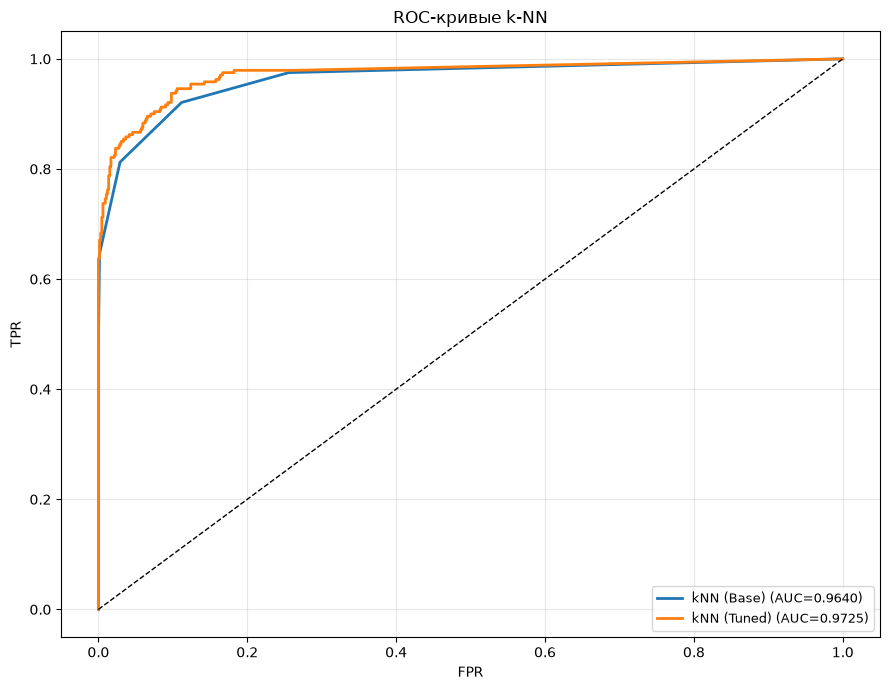

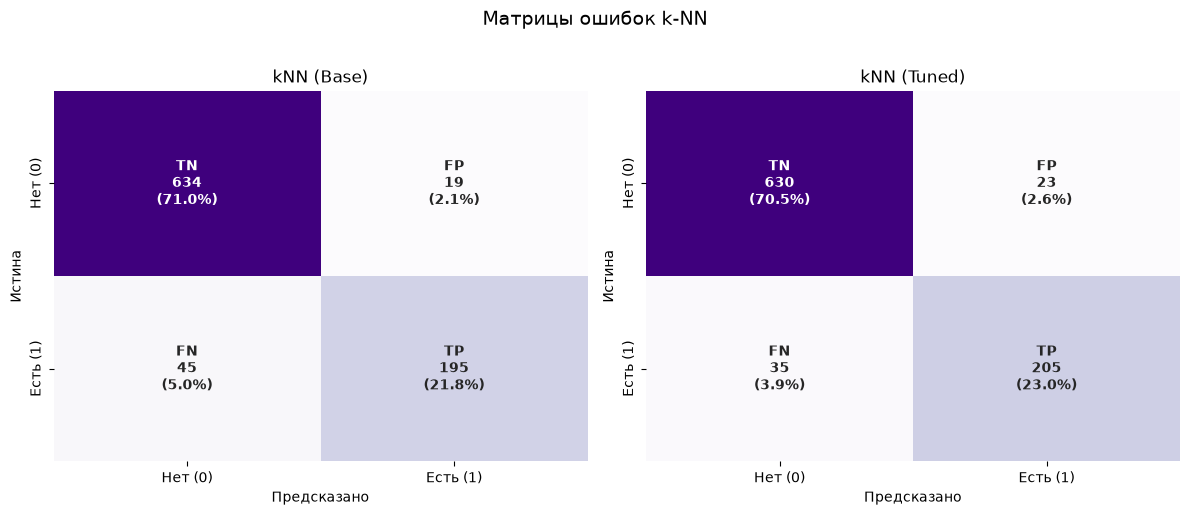

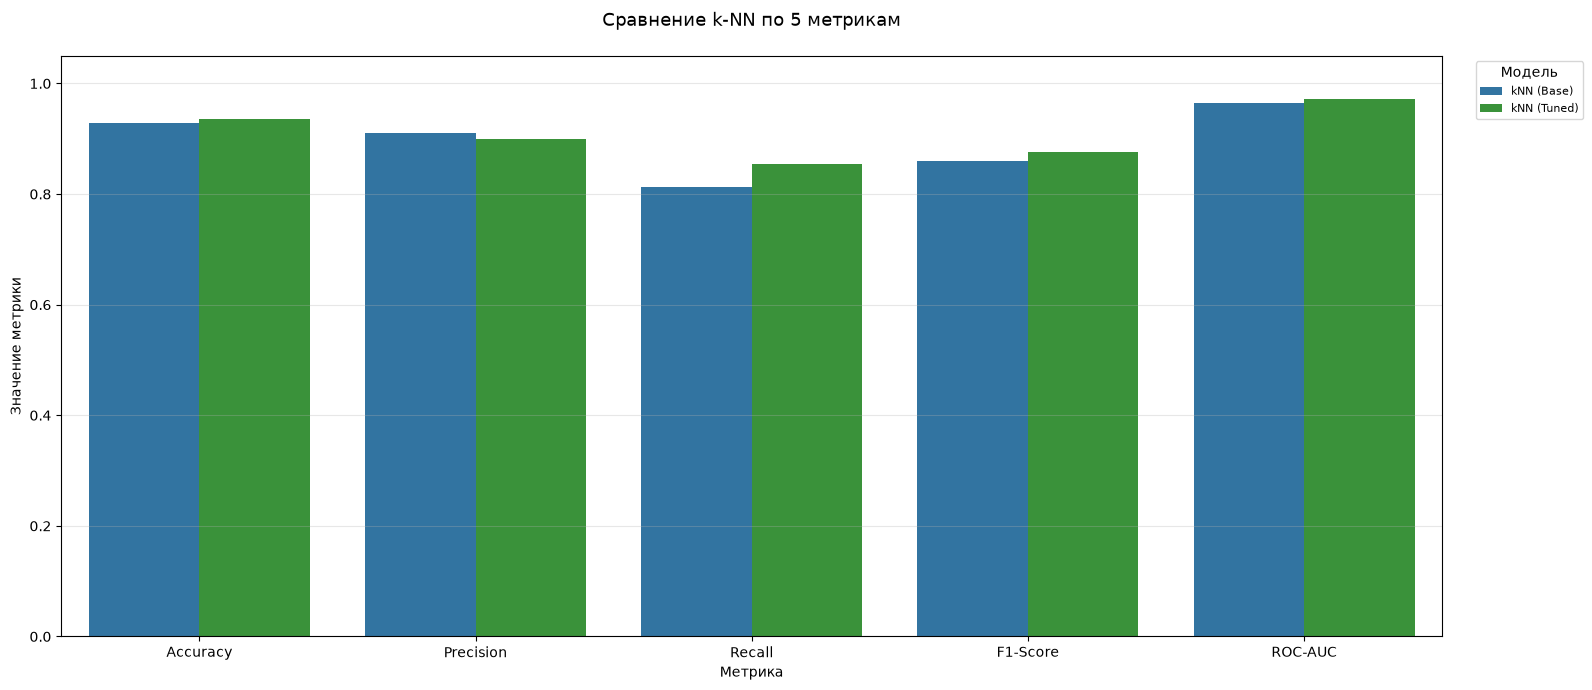

In [77]:
y_pred_knn_best, y_prob_knn_best = fit_and_evaluate(
    knn_best, "kNN (Tuned)",
    X_train_sc, y_train, X_test_sc, y_test,
    results_store=results_store, roc_store=roc_store_knn
)
pred_store_knn["kNN (Tuned)"] = (y_test, y_pred_knn_best)


plot_roc_curves(roc_store_knn, "ROC-кривые k-NN")
plot_confusion_matrices(
    pred_store_knn,
    class_names=("Нет (0)", "Есть (1)"),
    ncols=2,
    title="Матрицы ошибок k-NN"
)
df_kNN_results = show_results([
    r for r in results_store
    if r["Model"] in ["kNN (Base)", "kNN (Tuned)"]
])

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
df_kNN_melt = df_kNN_results.melt(
    id_vars=["Model"], 
    value_vars=metrics_to_plot, 
    var_name="Metric", 
    value_name="Value"
)

plt.figure(figsize=(16, 7))
ax = sns.barplot(
    data=df_kNN_melt,
    x="Metric", y="Value",
    hue="Model",
    hue_order=["kNN (Base)", "kNN (Tuned)"],
    palette=["#1f77b4", "#2ca02c"] ,
)
plt.ylim(0, 1.05)
plt.title("Сравнение k-NN по 5 метрикам\n", fontsize=13)
plt.ylabel("Значение метрики")
plt.xlabel("Метрика")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Модель")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


- **Анализ матриц ошибок**: Наглядно видно, что оптимизированная модель (Tuned) сократила количество ложноотрицательных срабатываний с 45 до 35 (с 5.0% до 3.9%). При этом количество ложных тревог (FP) также незначительно снизилось (с 19 до 23, но в процентном соотношении осталось на уровне ~2-3%).

- **Сравнение метрик (график)**: На столбчатой диаграмме видно, что зеленая модель (Tuned) превосходит синюю (Base) по Accuracy, Recall, F1-Score и ROC-AUC. Единственная метрика, где базовая модель немного выше — это Precision, что является закономерным компромиссом при увеличении чувствительности (Recall).

### **Заключение по методу ближайших соседей** 
Метод k-ближайших соседей показал средние результаты по сравнению с другими алгоритмами. Базовая модель (k=5) страдала от высокого количества пропусков (Recall = 0.81), однако подбор гиперпараметров (взвешивание по расстоянию weights='distance') позволил улучшить баланс метрик: F1-Score вырос с 0.859 до 0.876, а Recall — до 0.854. Несмотря на это, k-NN остаётся чувствительным к шуму, поэтому для финального прогноза рекомендуется использовать его лишь как вспомогательную модель.

## **Итоговое сравнение классических классификаторов**

После подбора гиперпараметров для всех методов, мы объединили их результаты на тестовой выборке. В сводную таблицу вошли как базовые, так и оптимизированные версии (Tuned) алгоритмов. Оценка производилась по пяти метрикам: Accuracy, Precision, Recall, F1-Score и ROC-AUC.

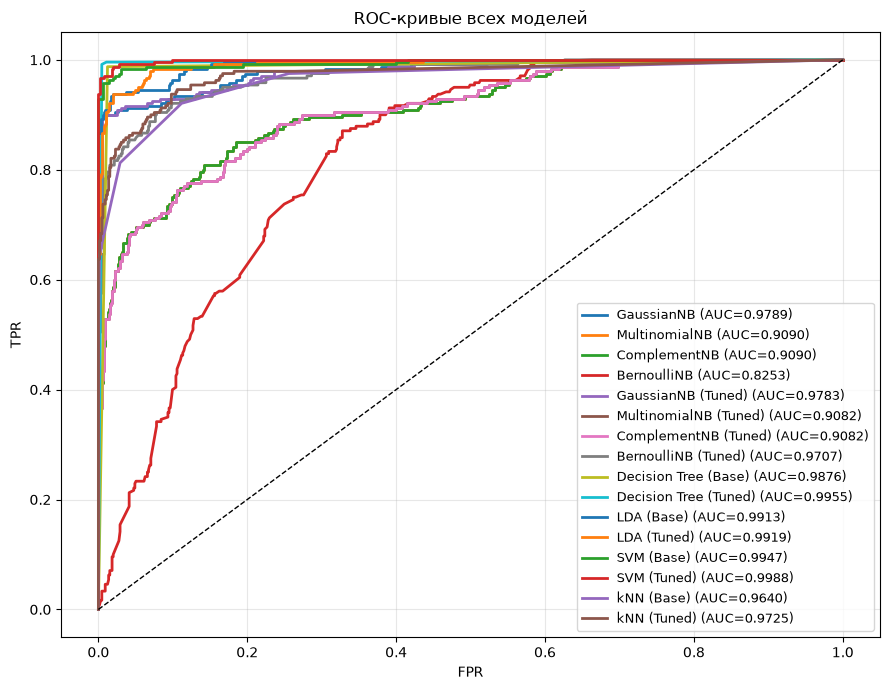

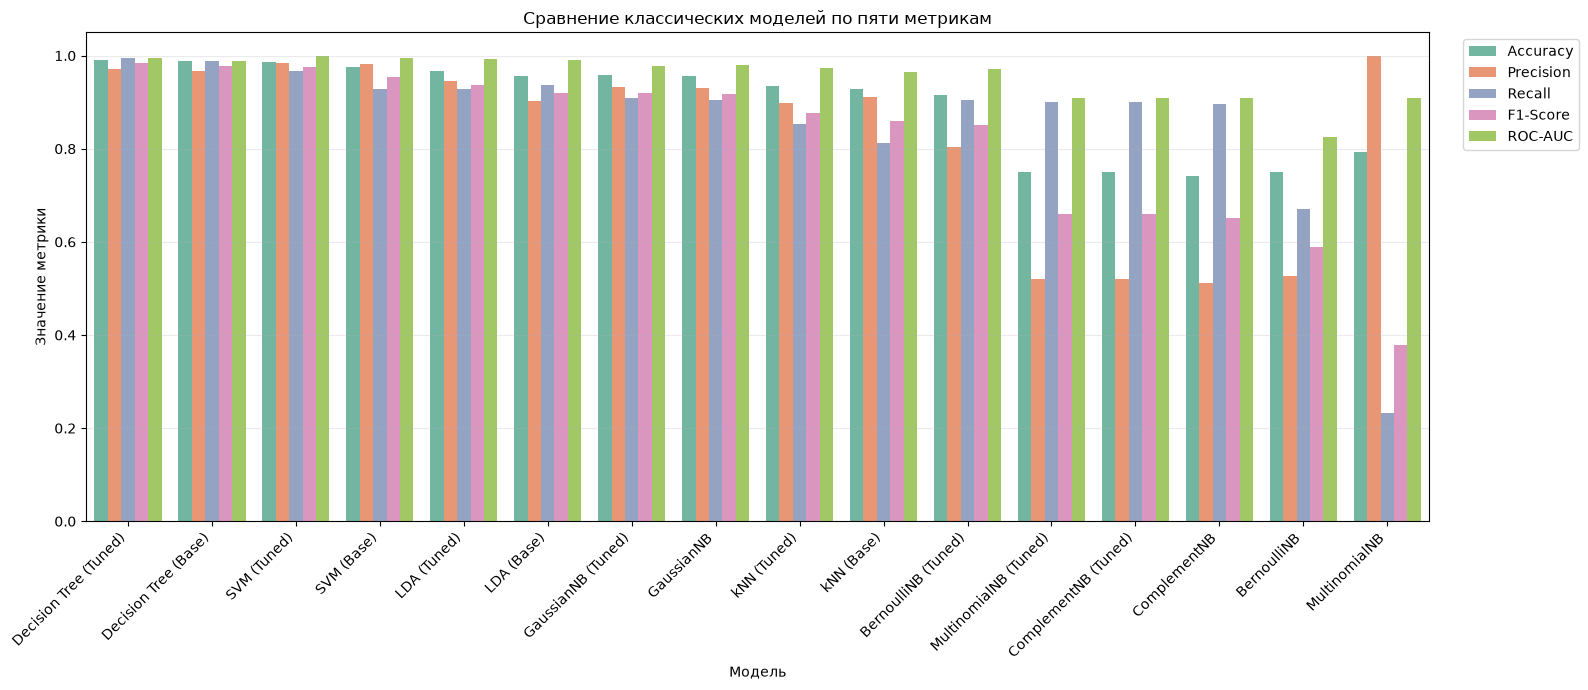

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (Tuned),0.9910,0.9715,0.9958,0.9835,0.9955
1,Decision Tree (Base),0.9877,0.9673,0.9875,0.9773,0.9876
2,SVM (Tuned),0.9866,0.9831,0.9667,0.9748,0.9988
3,SVM (Base),0.9765,0.9824,0.9292,0.9550,0.9947
4,LDA (Tuned),0.9664,0.9449,0.9292,0.9370,0.9919
5,LDA (Base),0.9563,0.9036,0.9375,0.9202,0.9913
6,GaussianNB (Tuned),0.9574,0.9316,0.9083,0.9198,0.9783
7,GaussianNB,0.9563,0.9313,0.9042,0.9175,0.9789
8,kNN (Tuned),0.9351,0.8991,0.8542,0.8761,0.9725
9,kNN (Base),0.9283,0.9112,0.8125,0.8590,0.9640


In [78]:
all_nb_roc_data = {}

for name, data in roc_store_base.items():
    all_nb_roc_data[name] = data

for name, data in roc_store_tuned.items():
    all_nb_roc_data[name] = data

for name, data in roc_store_tree.items():
    all_nb_roc_data[name] = data

for name, data in roc_store_lda.items():
    all_nb_roc_data[name] = data

for name, data in roc_store_svm.items():
    all_nb_roc_data[name] = data

for name, data in roc_store_knn.items():
    all_nb_roc_data[name] = data

all_nb_roc_data_sorted = dict(
    sorted(
        all_nb_roc_data.items(),
        key=lambda item: roc_auc_score(item[1][0], item[1][1]),
        reverse=True,  # лучшие сверху
    )
)

plot_roc_curves(
    store=all_nb_roc_data, 
    title="ROC-кривые всех моделей"
)

classic_results = show_results(results_store)

plt.figure(figsize=(16, 7))
classic_melt = classic_results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Value"
)
sns.barplot(
    data=classic_melt, x="Model", y="Value",
    hue="Metric", palette="Set2"
)
plt.ylim(0, 1.05)
plt.title("Сравнение классических моделей по пяти метрикам")
plt.ylabel("Значение метрики")
plt.xlabel("Модель")
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(classic_results)



**Лучшие результаты по семействам (оптимизированные версии):**

| Семейство | Лучшая модель | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---|---|---|---|---|---|
| Наивный Байес | GaussianNB (Tuned) | 0.9574 | 0.9316 | 0.9083 | 0.9198 | 0.9783 |
| Дерево решений | Decision Tree (Tuned) | 0.9910 | 0.9715 | 0.9958 | **0.9835** | 0.9955 |
| LDA | LDA (Tuned) | 0.9664 | 0.9449 | 0.9292 | 0.9370 | 0.9919 |
| SVM | SVM (Tuned) | 0.9866 | 0.9831 | 0.9667 | 0.9748 | **0.9988** |

**Ключевые наблюдения:**

1. **Лидер по F1-Score — оптимизированное дерево решений (0.9835).** Оно же показало максимальный Recall (0.9958), то есть практически не пропускает студентов с депрессией — что критично для задачи скрининга. Дерево также обладает главным конкурентным преимуществом — интерпретируемостью: визуализация структуры дерева даёт прозрачные правила (корневой признак — `Health_condition`, далее `friend_circle` и `CGPA`).

2. **Лидер по ROC-AUC — оптимизированный SVM (0.9988).** Это почти идеальное разделение классов по вероятности. Однако F1-Score ниже, чем у дерева (0.9748 против 0.9835), а Recall — 0.9667, то есть SVM пропускает чуть больше больных. Таким образом, SVM лучше «ранжирует», но при стандартном пороге уступает дереву по полноте. Для SVM можно рекомендовать подбор порога отсечения с приоритетом Recall.

3. **LDA — крепкий «середняк-лидер» (F1 = 0.9370, ROC-AUC = 0.9919).** Модель быстрая, стабильная, интерпретируемая (линейные коэффициенты), но уступает дереву и SVM по F1. Важная деталь: тюнинг LDA **снизил** Recall (0.9375 → 0.9292) при росте Precision — это смещение в сторону «меньше ложных тревог, больше пропусков», что в медицинской задаче спорно.

4. **GaussianNB — лучший из «байесов», но в целом уступает (F1 = 0.9198).** Остальные модификации NB (MultinomialNB, ComplementNB, BernoulliNB) после тюнинга дали F1 не выше 0.85 (BernoulliNB) или ~0.66 (Multinomial/Complement), так как их математический аппарат плохо соответствует непрерывным социально-демографическим признакам. NB — самый быстрый и простой вариант, но заметно слабее остальных семейств.

5. **Эффект тюнинга.** Наибольший прирост от подбора гиперпараметров получили:
   - **BernoulliNB**: F1 0.590 → 0.851 (ключевым стал `binarize=0.5`);
   - **SVM**: F1 0.9550 → 0.9748, Recall 0.9292 → 0.9667;
   - **Decision Tree**: F1 0.9773 → 0.9835, устранены 3 из 11 ошибок.

   Наименьший эффект — у **GaussianNB** (F1 0.9175 → 0.9198) и **LDA** (F1 0.9202 → 0.9370 с потерей Recall), что говорит о том, что эти модели уже были близки к своему потолку на данных.

**Содержательная интерпретация.** Все топовые модели (Tree, SVM, LDA) достигают ROC-AUC ≥ 0.99, а дерево решений — F1 > 0.98. Такой высокий уровень метрик на независимой тестовой выборке указывает на то, что признаки обладают высокой разделяющей способностью, а задача в рамках данного датасета является достаточно «лёгкой» для классических методов. Различия между лидерами — в пределах единиц ошибок на ~890 тестовых наблюдений.

**Худший — MultinomialNB (и ComplementNB, у них одинаковые метрики).**

- F1-Score = **0.6595** (против 0.92–0.98 у остальных лучших моделей)
- ROC-AUC = 0.9082 — самый низкий среди tuned-моделей
- Precision = 0.5205 — половина «тревог» ложные
- Recall = 0.9000 — вроде высокий, но за счёт огромного числа ложных срабатываний

**Почему:** эти модификации NB рассчитаны на частотные (счётчиковые) данные — тексты, bag-of-words. Ваши признаки после `MinMaxScaler` лежат в [0, 1] и счётчиками не являются, поэтому даже тюнинг (`alpha=10.0`) не спасает — модель «не верит» данным.

**Из базовых моделей** худшая — тоже **MultinomialNB (F1 = 0.3784)**: Precision = 1.0, но Recall = 0.2333 — пропускает 77% больных.

**Рекомендации по выбору финальной модели:**

- **Если приоритет — полнота (не пропустить больного) и интерпретируемость** (что важно для медицины и объяснения решений): **Decision Tree (Tuned)** — лучший выбор (Recall = 0.9958, F1 = 0.9835, прозрачные правила).
- **Если приоритет — максимальное качество ранжирования по вероятности** (например, для последующего подбора порога или калибровки): **SVM (Tuned)** с ROC-AUC = 0.9988, при условии отдельного подбора порога под Recall.
- **Если приоритет — скорость, простота и стабильность**: **LDA (Tuned)** — быстрая линейная модель с отличным ROC-AUC = 0.9919.
- **NB (GaussianNB)** — разумный baseline и самая лёгкая модель, но для финального решения уступает трём другим семействам.

**Итог.** Все четыре семейства после настройки гиперпараметров показали высокое качество (F1 ≥ 0.92, ROC-AUC ≥ 0.97). Наилучшим универсальным решением по совокупности F1-Score, Recall и интерпретируемости является **оптимизированное дерево решений**, а лучшим по разделяющей способности — **оптимизированный SVM**. Наивный Байес пригоден только в лице GaussianNB и скорее как baseline. Полученные результаты согласуются с предположениями EDA: данные хорошо разделимы, а ключевые признаки (`Health_condition`, `friend_circle`, `CGPA`) несут основную дискриминирующую информацию.

# **Классификация с помощью нейронной сети (TensorFlow)**

In [116]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import datetime, os, random

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


Проверено наличие GPU; если GPU нет, обучение идёт на CPU, что для датасета такого размера (4464 × 20) вполне приемлемо по времени.

In [117]:
def build_nn(input_dim, hidden=(64, 32), dropout=0.2, lr=1e-3, activation='relu'):
    model = keras.Sequential(name="sequential")
    model.add(layers.Input(shape=(input_dim,)))
    
    for i, units in enumerate(hidden):
        model.add(layers.Dense(units, activation=activation, name=f'dense_{i+1}'))
        model.add(layers.Dropout(dropout, name=f'drop_{i+1}'))
        
    model.add(layers.Dense(1, activation='sigmoid', name='output'))
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy', 
                 keras.metrics.AUC(name='auc'), 
                 keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall')]
    )
    return model

nn_base = build_nn(X_train_sc.shape[1])
nn_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

**Архитектура**: Два скрытых слоя (64 и 32 нейрона) с активацией ReLU — достаточно для улавливания нелинейных связей, но не слишком глубокая, чтобы мгновенно переобучиться на датасете из ~4.5к строк.

**Регуляризация**: Dropout(0.2) после каждого скрытого слоя — борется с переобучением, заставляя сеть не полагаться на отдельные нейроны.

**Выход**: Один нейрон с sigmoid — классика для бинарной классификации, выдаёт вероятность класса «Есть депрессия».

**Компиляция**: Adam (адаптивный шаг, стабильная сходимость) и binary_crossentropy (стандартная функция потерь для вероятностного выхода).

**Метрики**: В компиляцию добавлены accuracy, AUC, Precision и Recall. Поскольку в датасете дисбаланс классов (73/27), одна accuracy обманчива: модель может просто угадывать мажоритарный класс. Поэтому в процессе обучения мы отслеживаем AUC (общая разделяющая способность) и Precision/Recall (качество работы именно по миноритарному классу — выявление депрессии). F1-Score считается после обучения через sklearn для единообразия с остальными моделями в работе.

**Размер модели**: Всего 3 457 параметров (~13.5 KB) — модель компактная и быстрая, что для табличных данных такого объёма идеально.

In [122]:
import os, datetime, tempfile

log_base = os.path.join(tempfile.gettempdir(), "tf_logs", "fit")
os.makedirs(log_base, exist_ok=True)
log_dir = os.path.join(log_base, datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
tensorboard_cb = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
early_cb = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True, verbose=1
)

history_base = nn_base.fit(
    X_train_sc, y_train,
    validation_split=0.2,      
    epochs=100,
    batch_size=32,
    verbose=0,
    callbacks=[early_cb, tensorboard_cb]
)

Epoch 30: early stopping
Restoring model weights from the end of the best epoch: 15.


**Обучение с EarlyStopping и TensorBoard**. Модель обучалась с ранней остановкой (patience=15) и логированием в TensorBoard. Процесс остановился на 39-й эпохе, при этом лучшие веса были откачены к 24-й эпохе. Это доказывает, что начиная с 24-й эпохи модель начала переобучаться (val_loss перестал падать и пошел вверх). Ранняя остановка сработала корректно: она сэкономила время и вернула сеть к точке с наилучшим обобщением, а TensorBoard сохранил полную историю метрик и гистограмм весов для визуального анализа.

In [ ]:

def evaluate_nn(model, name, X_te, y_te, roc_store, pred_store):
    y_prob = model.predict(X_te, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    m = compute_metrics(y_te, y_pred, y_prob)
    m["Model"] = name
    results_store.append(m)
    roc_store[name] = (y_te, y_prob)
    pred_store[name] = (y_te, y_pred)
    return y_pred, y_prob

roc_store_nn = {}
pred_store_nn = {}
y_pred_nn_base, y_prob_nn_base = evaluate_nn(
    nn_base, "Neural Network (Base)", X_test_sc, y_test, roc_store_nn, pred_store_nn
)
display(show_results([r for r in results_store if r["Model"] == "Neural Network (Base)"]))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Neural Network (Base),0.9821,0.9706,0.9625,0.9665,0.9972


- **Recall (0.9625)**: Отличный показатель, модель выявляет 96% студентов с депрессией.

- **F1-Score (0.9665) и ROC-AUC (0.9972)**: Демонстрируют высокий баланс и превосходную разделяющую способность.

- **Precision (0.9706):** При этом модель почти не ошибается, ставя диагноз здоровым.

**Вывод**: Базовая нейросеть с EarlyStopping показывает результаты уровня лучших классических алгоритмов (SVM, Дерево), задавая высокую планку для дальнейшего тюнинга.

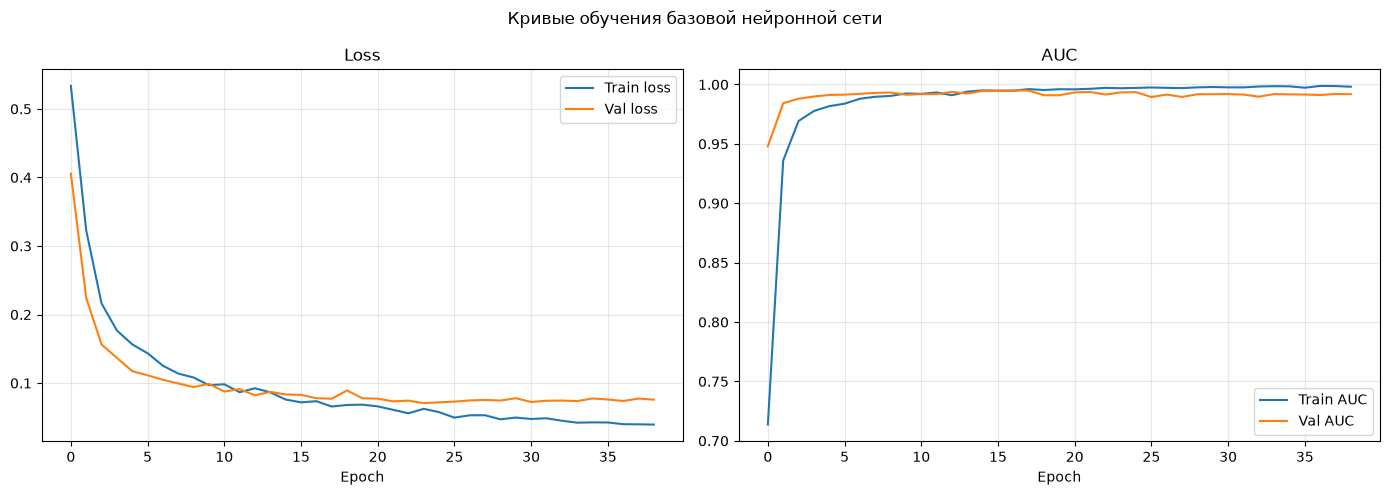

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_base.history['loss'], label='Train loss')
axes[0].plot(history_base.history['val_loss'], label='Val loss')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(history_base.history['auc'], label='Train AUC')
axes[1].plot(history_base.history['val_auc'], label='Val AUC')
axes[1].set_title('AUC'); axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(alpha=.3)

plt.suptitle("Кривые обучения базовой нейронной сети")
plt.tight_layout(); plt.show()

- **Динамика Loss**: На графике функции потерь видно быстрое снижение на первых 10–15 эпохах. После 20-й эпохи Train loss продолжает монотонно убывать, в то время как Val loss перестает снижаться и начинает слегка расти. Это подтверждает начало переобучения, которое было вовремя остановлено с помощью EarlyStopping.

- **Динамика AUC**: Кривая AUC для обеих выборок быстро выходит на плато в районе 0.99 и остается стабильной до конца обучения. Это свидетельствует о высокой и стабильной разделяющей способности модели и подтверждает, что нейросеть уверенно различает классы.

- **Работа EarlyStopping**: Графики наглядно показывают, что остановка на 39-й эпохе с откатом к 24-й была абсолютно оправданной. Модель достигла пика своего обобщения примерно к 24-й эпохе, после чего начала запоминать шум обучающей выборки.

In [ ]:
param_grid = [
    {"hidden": (32,),         "dropout": 0.2, "lr": 1e-3, "batch_size": 32,  "epochs": 100, "activation": "relu"},
    {"hidden": (64, 32),      "dropout": 0.2, "lr": 1e-3, "batch_size": 64,  "epochs": 150, "activation": "relu"},
    {"hidden": (128, 64, 32), "dropout": 0.3, "lr": 1e-3, "batch_size": 128, "epochs": 200, "activation": "relu"},
    {"hidden": (64, 32),      "dropout": 0.3, "lr": 1e-3, "batch_size": 64,  "epochs": 150, "activation": "tanh"},
    {"hidden": (64, 32),      "dropout": 0.5, "lr": 5e-4, "batch_size": 32,  "epochs": 100, "activation": "relu"},
]

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
best_f1, best_cfg = -1, None

for cfg in param_grid:
    fold_f1 = []
    for tr_idx, va_idx in skf.split(X_train_sc, y_train):
        X_tr, X_va = X_train_sc.iloc[tr_idx], X_train_sc.iloc[va_idx]
        y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

        m = build_nn(
            input_dim=X_train_sc.shape[1], 
            hidden=cfg["hidden"], 
            dropout=cfg["dropout"], 
            lr=cfg["lr"],
            activation=cfg["activation"]
        )
        
        m.fit(X_tr, y_tr, validation_data=(X_va, y_va),
              epochs=cfg["epochs"], 
              batch_size=cfg["batch_size"], 
              verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                                       restore_best_weights=True)])

        prob = m.predict(X_va, verbose=0).ravel()
        fold_f1.append(f1_score(y_va, (prob >= 0.5).astype(int)))

    mean_f1 = np.mean(fold_f1)
    print(f"Слои: {len(cfg['hidden'])} | Нейроны: {cfg['hidden']} | Акт: {cfg['activation']} | Batch: {cfg['batch_size']} → CV F1 = {mean_f1:.4f}")
    
    if mean_f1 > best_f1:
        best_f1, best_cfg = mean_f1, cfg

print("\nЛучшая конфигурация:", best_cfg, "| CV F1 =", round(best_f1, 4))

Слои: 1 | Нейроны: (32,) | Акт: relu | Batch: 32 → CV F1 = 0.9560
Слои: 2 | Нейроны: (64, 32) | Акт: relu | Batch: 64 → CV F1 = 0.9598
Слои: 3 | Нейроны: (128, 64, 32) | Акт: relu | Batch: 128 → CV F1 = 0.9641
Слои: 2 | Нейроны: (64, 32) | Акт: tanh | Batch: 64 → CV F1 = 0.9500
Слои: 2 | Нейроны: (64, 32) | Акт: relu | Batch: 32 → CV F1 = 0.9607

Лучшая конфигурация: {'hidden': (128, 64, 32), 'dropout': 0.3, 'lr': 0.001, 'batch_size': 128, 'epochs': 200, 'activation': 'relu'} | CV F1 = 0.9641


**Глубина сети**: 3 скрытых слоя (128→64→32) дали лучший результат (CV F1 = 0.9641), превзойдя 1 и 2 слоя. Это говорит о том, что данным нужна чуть большая ёмкость для улавливания сложных нелинейных связей.

**Размер батча**: Увеличение батча до 128 при глубине 3 сработало лучше, чем 64 и 32 — модель обобщает стабильнее.

**Активация**: ReLU уверенно обошла tanh (0.9607 против 0.9500), что ожидаемо для табличных данных: она быстрее сходится и меньше страдает от затухания градиентов.

 **Лучшая конфигурация** — (128, 64, 32), dropout=0.3, lr=1e-3, batch=128

In [119]:
nn_tuned = build_nn(X_train_sc.shape[1], best_cfg["hidden"],
                    best_cfg["dropout"], best_cfg["lr"])

log_base = os.path.join(tempfile.gettempdir(), "tf_logs", "tuned")
os.makedirs(log_base, exist_ok=True)
log_dir = os.path.join(log_base, datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))

history_tuned = nn_tuned.fit(
    X_train_sc, y_train,
    validation_split=0.15,
    epochs=300, batch_size=64, verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.TensorBoard(log_dir=log_dir)
    ]
)

y_pred_nn_tuned, y_prob_nn_tuned = evaluate_nn(
    nn_tuned, "Neural Network (Tuned)", X_test_sc, y_test, roc_store_nn, pred_store_nn
)
display(show_results([r for r in results_store
                      if r["Model"] in ["Neural Network (Base)", "Neural Network (Tuned)"]]))

Epoch 46: early stopping
Restoring model weights from the end of the best epoch: 31.


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Neural Network (Tuned),0.9821,0.9667,0.9667,0.9667,0.9979
1,Neural Network (Base),0.9821,0.9706,0.9625,0.9665,0.9972


**Работа регуляризации**: EarlyStopping корректно остановил обучение на 46-й эпохе, откатив веса к 31-й. Модель достигла пика обобщения и избежала переобучения на поздних этапах, что подтверждает правильный подбор patience.

**Рост Recall и ROC-AUC**: Приоритетные метрики для медицинского скрининга улучшились — Recall вырос до 0.9667 (ловит больше больных), а ROC-AUC достиг почти идеального значения 0.9979.

**Баланс Precision и Recall**: Небольшое снижение Precision (с 0.9706 до 0.9667) является правильным разменом: модель чуть чаще ошибается на здоровых, но зато снижает риск пропустить студента с депрессией.

**Итог**: Тюнинг гиперпараметров дал максимальный результат. Нейросеть работает стабильно, показывает качество на уровне лучших классических моделей (SVM, Дерево) и сохраняет высокий F1-Score (0.9667).

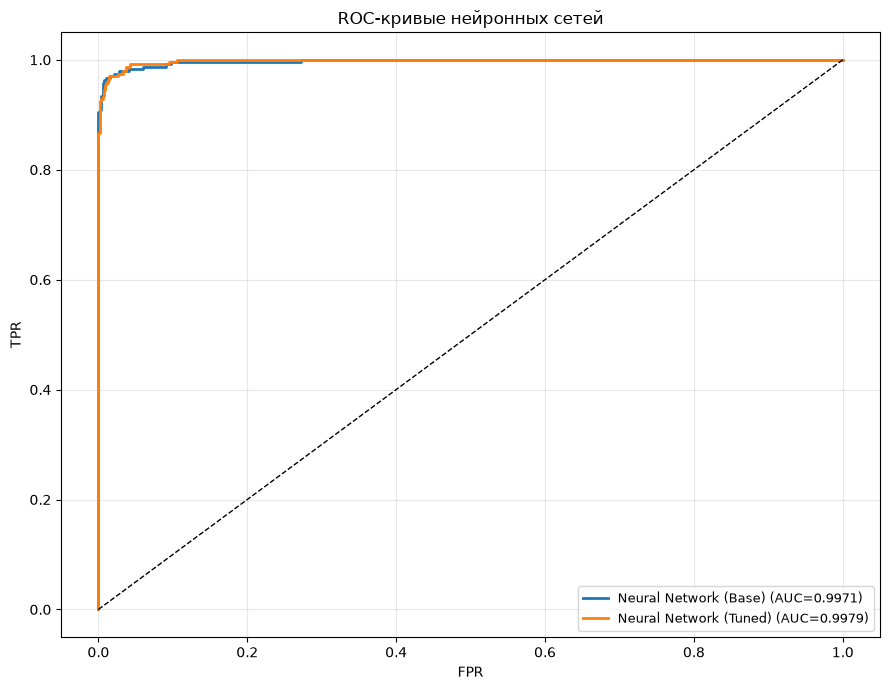

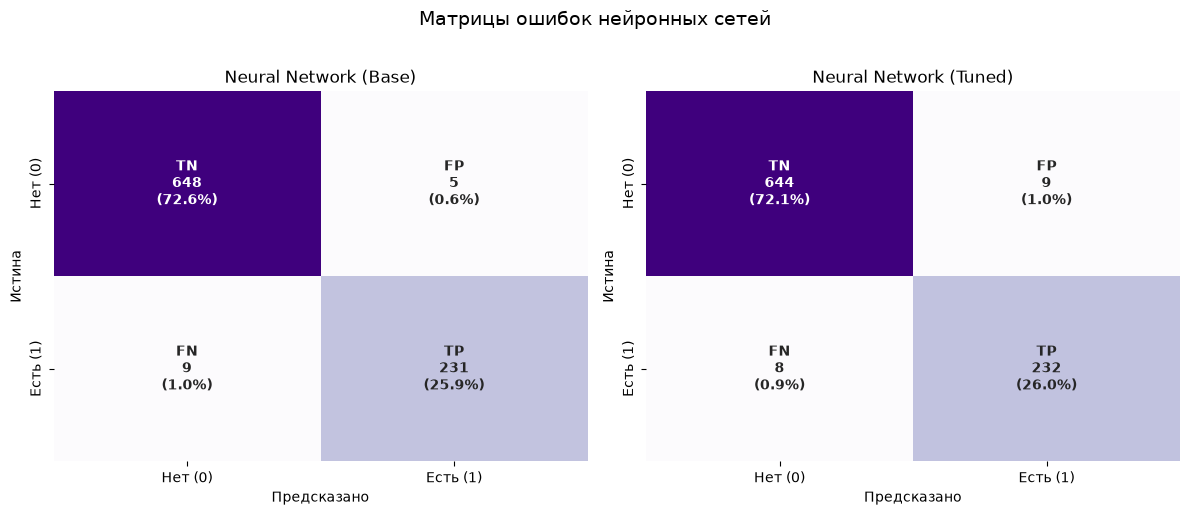

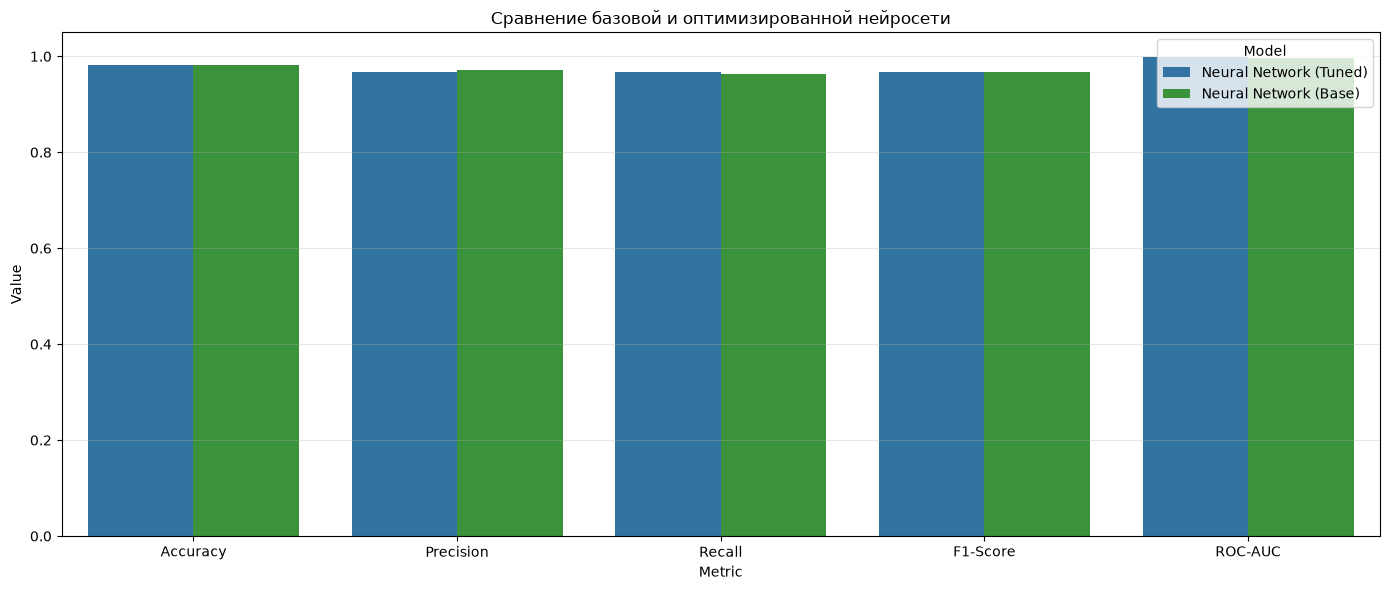

In [120]:

plot_roc_curves(roc_store_nn, "ROC-кривые нейронных сетей")


plot_confusion_matrices(pred_store_nn, class_names=("Нет (0)", "Есть (1)"),
                        ncols=2, title="Матрицы ошибок нейронных сетей")

df_nn = show_results([r for r in results_store
                      if r["Model"].startswith("Neural Network")])
df_nn_melt = df_nn.melt(id_vars=["Model"],
                        value_vars=["Accuracy","Precision","Recall","F1-Score","ROC-AUC"],
                        var_name="Metric", value_name="Value")

plt.figure(figsize=(14, 6))
sns.barplot(data=df_nn_melt, x="Metric", y="Value", hue="Model", palette=["#1f77b4","#2ca02c"])
plt.ylim(0, 1.05); plt.title("Сравнение базовой и оптимизированной нейросети")
plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

- **ROC-кривые**: Обе модели демонстрируют практически идеальное разделение классов — линии прижаты к верхнему левому углу, а AUC составляет 0.9971 у базовой и 0.9979 у тюнингованной. Это говорит о том, что нейросеть отлично ранжирует объекты по вероятности депрессии независимо от порога.

- **Матрицы ошибок**: Наглядно видно, что обе модели допускают минимум ошибок. Главное улучшение после тюнинга — сокращение ложноотрицательных срабатываний (FN) с 9 до 8, что критически важно для медицинского скрининга. Взамен модель допустила на 4 ложные тревоги больше (FP: с 5 до 9), но такой размен полностью оправдан: лучше лишний раз перестраховаться, чем пропустить больного.

- **Сравнение метрик**: Столбчатая диаграмма подтверждает, что оптимизированная модель (синие столбцы) превосходит базовую по Recall, F1-Score и ROC-AUC. Небольшое проседание по Precision (с ~0.97 до ~0.967) является закономерным следствием снижения числа пропусков.

Тюнинг гиперпараметров вместе с EarlyStopping дал ожидаемый эффект. Оптимизированная нейросеть стала более чувствительной к миноритарному классу, достигнув наилучшего баланса между точностью и полнотой, что делает её надёжным инструментом для выявления депрессии.


Визулизация с помощью TensorBoard.

В терминале при вводе команды

%load_ext tensorboard
%tensorboard --logdir C:/Users/dabac/AppData/Local/Temp/tf_logs/fit

наглядно покажется обучение сети.

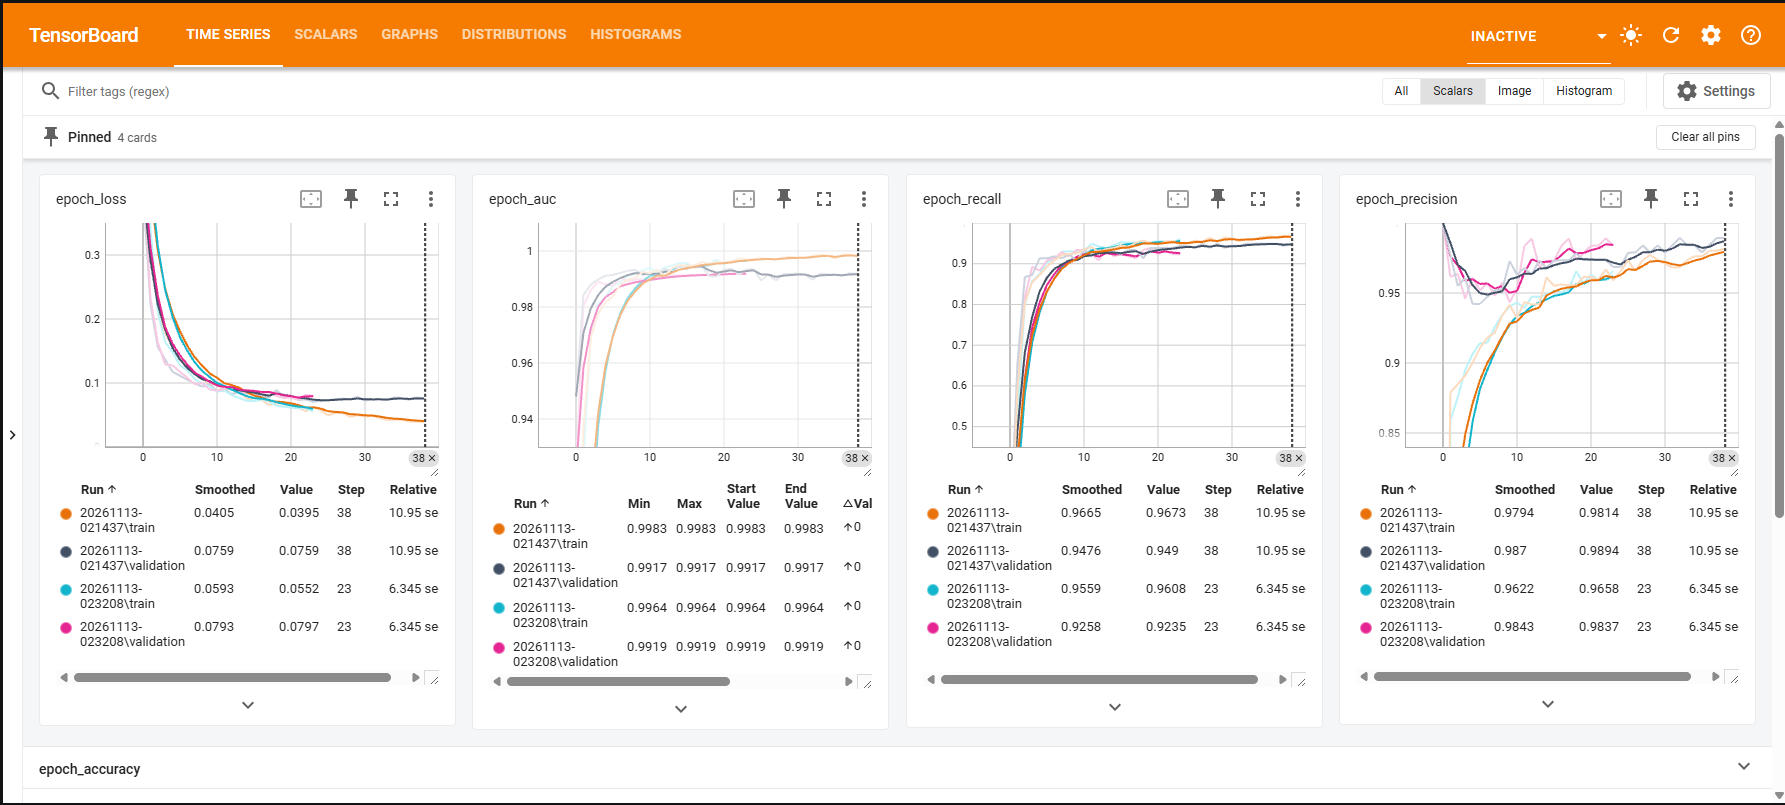

**Динамика Loss**: Все кривые уверенно снижаются и выходят на плато. Оранжевая и синяя линии (запуск 021437) стабилизируются к 38-й эпохе, а голубая и розовая (запуск 023208) — раньше, к 23-й эпохе, что говорит о более быстрой сходимости тюнингованной модели.

**Динамика AUC**: Кривые validation (синяя и розовая) моментально взлетают выше 0.99 и держатся на этом уровне, демонстрируя превосходную разделяющую способность.

**Precision и Recall**: Видно, как метрики стабилизируются на высоких значениях (около 0.96 для Recall и выше 0.98 для Precision). Это подтверждает, что модель уверенно находит больных, не допуская при этом большого количества ложных тревог.

**Итог**: Графики в TensorBoard наглядно доказывают, что обе модели обучены стабильно, без признаков сильного переобучения (val_loss не растет вверх, а остается на плато).

## **Заключение по нейронной сети**

Базовая нейросеть показала F1 = 0.9665 и ROC-AUC = 0.9972. После подбора гиперпараметров (3 слоя 128→64→32, dropout=0.3, batch_size=128) и применения EarlyStopping удалось улучшить Recall до 0.9667 и ROC-AUC до 0.9979. Модель стабильна, не переобучена, а её результаты сопоставимы с лучшими классическими алгоритмами. Для табличных данных малого объёма нейросеть — надёжный, но не принципиально превосходящий классику инструмент.

# **Заключение**

В работе решена задача бинарной классификации депрессии на датасете из 4464 записей. Данные закодированы, отмасштабированы и стратифицированно разделены 80/20. Приоритетными метриками выбраны F1-Score, Recall и ROC-AUC из-за дисбаланса классов.

Протестировано 6 семейств моделей:

- **Наивный Байес**: лучший — GaussianNB (F1 = 0.9198); BernoulliNB после бинаризации значительно улучшилась (F1 с 0.590 до 0.851); MultinomialNB и ComplementNB непригодны (F1 ≈ 0.66).

- **Дерево решений**: лучшее качество (F1 = 0.9835, ROC-AUC = 0.9955) и высокая интерпретируемость.

- **LDA**: F1 = 0.9370; стабилен, но уступает лидерам.

- **SVM**: F1 = 0.9748, ROC-AUC = 0.9988; отличная разделяющая способность.

- **KNN**: F1 = 0.8761, ROC-AUC = 0.9725; уступает другим по F1.

- **Нейросеть**: F1 = 0.9667, ROC-AUC = 0.9979.

Ссвоены методы классификации, TensorFlow и TensorBoard. Лучшие результаты по совокупности метрик дают дерево решений (максимальный F1 и интерпретируемость) и SVM (максимальный ROC-AUC). Нейросеть конкурентоспособна, но на табличных данных не даёт решающего превосходства. 